# Exploring the OpenAI Research Catalog

An exploratory data analysis of the [OpenAI Math dataset](https://www.kaggle.com/datasets/grimespoint/openai-bulk-release-of-mathematical-papers-dataset) by [brkln](https://github.com/hyperphantasia)

Summer 2026 will be remembered by the mathematics community, of course telltale signs were already in the air but it all accelerated and became a brutal reality when OpenAI announced that its models had solved one of math's most famous problems. A solution<sup>[here](https://www.nature.com/articles/d41586-026-02842-5) and [here](https://www.scientificamerican.com/article/did-openai-solve-the-wrong-navier-stokes-problem/)</sup> to the Navier-Stokes problem was produced through the collective efforts of a 10,000+ strong agentic swarm.
Then, a few weeks later a different approach produced almost every one of the results of a [bulk release](https://en.wikipedia.org/wiki/OpenAI_bulk_release_of_mathematical_papers) of papers in response to one (or just a few) prompt handed to a single AI agent. This was less covered by the press but it represents a striking difference from OpenAI's earlier blockbuster approach and left the Math community dizzy and [puzzled](https://www.quantamagazine.org/updates/transformation/#167703). But what is this bulk release really about ?

While it is up to the math community to assess wether this represents if this catalog represents significant breakthrough, it is good to have a glance at the unsupervized material OpenAI published online (some of it was later removed). This notebook provides the analytical picture. 

The catalog bundles **721 algoscripts** (I would not consider them as *[manuscripts](https://en.wikipedia.org/wiki/Manuscript)*) grouped into **373 result families** (one family = one headline result, possibly proved/documented by several papers) across 17 areas of mathematics and theoretical computer science.

### Data dictionary 

One row per paper:

| Column | Meaning |
|---|---|
| `paper_name` | Title of the publication |
| `description` | Abstract / summary of that paper |
| `main_subject` | One of 17 areas taken from the catalog overview |
| `msc_primary` | MSC 2020 codes of the family **Same for all papers in a family** |
| `msc_primary_section` | Name of the first 2-digit MSC section of `msc_primary` |
| `msc_secondary` | MSC 2020 codes of the family (`;`-separated). **Same for all papers in a family** |
| `result_family_number` | Catalog entry number (001-378, with a few gaps) |
| `result_family_title`, `result_family_description` | Short title / full statement of the headline result |
| `keywords` | Up to 6 auto-extracted key phrases (`;`-separated) |
| `paper_url` | Link to the source PDF |
| `result_family_lean_url` | Link to the Lean formalisation notes, when the catalog provides one |

### Methodological caveats 

(read before drawing conclusions)

- **Subject** : `main_subject`, is the editorial (OpenAI original) grouping of the catalog (17 values). **MSC section** are first two digits of an MSC code. They measure different things: the subject is *where the catalog files a result*, the MSC code is *what the mathematics is about*. They often agree, the disagreements are interesting (§4).
- Many statistics are computed **at family level** (to avoid counting a result several times) and this is always stated.
- **MSC codes are curated per family**, not per algoscript. They represent a reasonable expert-style classification but not an authoritative one. Analyses in §4 describe *this classification*.
- **Keywords** are machine-extracted** : RAKE-style phrases ranked by TF-IDF. This approach can output noise, it is not a ground truth.
-  **Release dates** are parsed from the algoscript folder name inside `paper_url` (e.g. `…-October-7-2026/`). It is the date of the folder, which is the best available proxy for when the algoscript entered the catalog.

## Contents

| # | Question | Where |
|---|----------|-------|
| 1 | How big is each subject? How concentrated are algoscripts in families ? | [Overview](#the-collection-at-a-glance) |
| 2 | When were the papers released and in which order did subjects appear ? | [Timeline](#release-timeline) |
| 3 | What *kind* of claims are made (resolutions, counterexamples, sharp bounds, algorithms..) ? | [Anatomy of a result](#Anatomy-of-a-result) |
| 4 | How does the collection map onto the **Mathematics Subject Classification 2020**? Which fields are bridged ? | [MSC 2020](#Mathematics-Subject-Classification) |
| 5 | What does the *text* say? Does it re-discover the subject taxonomy on its own? Which papers sit between fields ? | [Text analytics](#Text-analytics:-vocabulary,-embeddings,-clusters,-topics) |
| 6 | Which concepts recur and connect subjects ? | [Keywords](#Keywords-and-concept-network) |
| 7 | How do I look up a paper / family ? | [Explorer helpers](#Interactive-explorer-helpers) |
| 8 | What are the headline findings ? | [Findings](#Key-findings-and-limitations) |

Key findings:

- Families are mostly small with 55% of result families that have just one algoscript and only a few are crowded.
- Results often cross mathematical areas: 58% of families span at least two MSC sections. The sections form five communities.
- 67% of families mention a named conjecture or problem. About 27% are tagged as negative or disproof-type results, especially in mathematical logic.

## Setup

**Requirements** (Python ≥ 3.10): `pandas>=2`, `numpy`, `matplotlib`, `seaborn`, `scikit-learn`, `networkx`, `scipy`.

In [1]:
# pip install pandas numpy matplotlib seaborn scikit-learn networkx scipy jupyterlab

### Imports

In [2]:
import re
import math
import textwrap
import warnings
import itertools

from pathlib import Path
from cycler import cycler
from collections import Counter, defaultdict

import numpy as np
import pandas as pd

import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
import networkx as nx

from scipy.stats import chi2_contingency
from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.decomposition import TruncatedSVD, NMF
from sklearn.manifold import TSNE
from sklearn.cluster import KMeans
from sklearn.preprocessing import normalize
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score, silhouette_samples
from IPython.display import display, Markdown

### Setup

Global configuration, plotting style and small helpers. Change `DATA_PATH` if the file lives elsewhere.

In [3]:
warnings.filterwarnings("ignore")

# ------------------------- configuration -------------------------
DATA_PATH = Path("OpenAI_math_research_catalog.csv")
SEED = 42
SAVE_FIGS = False                        # True -> write PNGs to FIG_DIR
FIG_DIR = Path("figures")

EXPORT_ENRICHED = False  # True -> write OpenAI_math_analysis.csv
np.random.seed(SEED)

# ------------------------- style -------------------------
mpl.rcParams["axes.prop_cycle"] = cycler(
    color=mpl.color_sequences["okabe_ito"])
mpl.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 160,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titleweight": "bold", "axes.titlesize": 13, "axes.labelsize": 11,
})
plt.style.use("fivethirtyeight")
sns.set_theme(style="darkgrid", context="notebook", font_scale=1.0)
sns.set_palette(mpl.color_sequences["okabe_ito"])

pd.set_option("display.max_colwidth", 110, "display.width",
              200, "display.max_rows", 120)


def finish(fig, name):
    """Tight layout, optionally save, show."""
    fig.tight_layout()
    if SAVE_FIGS:
        FIG_DIR.mkdir(exist_ok=True)
        fig.savefig(FIG_DIR / f"{name}.png", bbox_inches="tight")
    plt.show()


def takeaway(text):
    """Render a highlighted, data-driven takeaway under a figure/table."""
    display(Markdown("> **Takeaway.** " + text))


def pct(x, d=1): return f"{100*x:.{d}f}%"


print("pandas", pd.__version__, "| numpy",
      np.__version__, "| networkx", nx.__version__)

pandas 3.1.1 | numpy 2.5.4 | networkx 3.7


## Load and audit the data

Load the CSV with `keep_default_na=False` so that *empty strings stay empty* (a few families have no secondary MSC code so they must not become `NaN` silently), then derive helper columns:

- list-valued columns (`kw`, `msc_sec_list`, `msc_all_sections`),
- `subject` : a short label for plots,
- `release` : the release date parsed from the URL (two folder-name formats occur: `Month-D-YYYY` and ISO `YYYY-MM-DD`),
- word counts of descriptions,
- a **family table** `fam` (one row per result family).

In [4]:
df = pd.read_csv(DATA_PATH, encoding="utf-8-sig",
                 dtype={"msc_primary": str}, keep_default_na=False)

EXPECTED = ["paper_name", "description", "main_subject", "msc_primary", "msc_secondary", "msc_primary_section",
            "result_family_number", "result_family_title", "result_family_description", "keywords", "paper_url",
            "result_family_lean_url"]
assert not set(EXPECTED) - \
    set(df.columns), f"missing columns: {set(EXPECTED) - set(df.columns)}"

SHORT = {"Algebraic and complex geometry": "Alg. & complex geometry", "Dynamical systems and ergodic theory": "Dynamics & ergodic th.",
         "Probability and statistical mechanics": "Probability & stat. mech.", "Theoretical computer science": "Theoretical CS",
         "Partial differential equations": "PDE", "Real and complex analysis": "Real & complex analysis",
         "Convex and metric geometry": "Convex & metric geom.", "Mathematical physics": "Math. physics",
         "Mathematical logic": "Math. logic", "Differential geometry": "Differential geom."}
df["subject"] = df.main_subject.map(lambda s: SHORT.get(s, s))


def parse_release(url):
    # ...-October-7-2026/
    m = re.search(r"-([A-Z][a-z]+)-(\d{1,2})-(\d{4})/", url)
    if m:
        return pd.to_datetime(f"{m[1]} {m[2]} {m[3]}", format="%B %d %Y")
    # ...-2026-09-24/
    m = re.search(r"-(\d{4})-(\d{2})-(\d{2})/", url)
    return pd.to_datetime(f"{m[1]}-{m[2]}-{m[3]}") if m else pd.NaT


def split_list(s): return [x.strip() for x in s.split(";") if x.strip()]


df["release"] = df.paper_url.map(parse_release)
df["msc_section"] = df.msc_primary.str[:2]
df["kw"] = df.keywords.map(split_list)
df["msc_sec_list"] = df.msc_secondary.map(split_list)
df["msc_all_sections"] = [sorted({p[:2]} | {c[:2] for c in s})
                          for p, s in zip(df.msc_primary, df.msc_sec_list)]
df["n_words"] = df.description.str.split().str.len()
df["fam_n_words"] = df.result_family_description.str.split().str.len()

fam = (df.groupby("result_family_number")
         .agg(title=("result_family_title", "first"), description=("result_family_description", "first"),
              subject=("subject", "first"), main_subject=("main_subject", "first"),
              msc_primary=("msc_primary", "first"), msc_section=("msc_section", "first"),
              msc_sections_all=("msc_all_sections", "first"), n_papers=("paper_name", "size"),
              first_release=("release", "min"), last_release=("release", "max"),
              has_lean=("result_family_lean_url", lambda s: bool(s.iloc[0])))
         .reset_index().rename(columns={"result_family_number": "family"}))
print(f"{len(df)} algoscripts · {len(fam)} families · {df.subject.nunique()} subjects")
df.head(3).T

721 algoscripts · 373 families · 17 subjects


,0,1,2
paper_name,Milne's rationality conjecture for abelian varieties,Exact Birch–Swinnerton-Dyer Formula from Low Selmer Corank,The Selmer converse for elliptic curves at every prime
description,"We prove Milne's rationality conjecture for abelian varieties, including residue characteristic 2. After g...",We prove the full Birch–Swinnerton-Dyer leading-term formula for every elliptic curve over ℚ whose full q-...,We prove the Selmer converse in coranks zero and one for every elliptic curve over ℚ and every prime p: if...
main_subject,Number theory,Number theory,Number theory
msc_primary,14C25,11G40,11G40
msc_primary_section,Algebraic geometry,Number theory,Number theory
msc_secondary,14C30; 14K22,11G05; 11R23,11G05; 11R23
result_family_number,1,2,2
result_family_title,Milne’s rationality conjecture and algebraic specialization,The full BSD formula from low Selmer corank,The full BSD formula from low Selmer corank
result_family_description,Proves Milne's rationality conjecture for abelian varieties over ℚ̅ with good reduction: specialized Hodge...,Proves the full Birch–Swinnerton-Dyer leading-term formula for every elliptic curve over ℚ whose full q-po...,Proves the full Birch–Swinnerton-Dyer leading-term formula for every elliptic curve over ℚ whose full q-po...
keywords,abelian varieties; rationality conjecture; Hodge theorem; specialized Hodge class; residue characteristic;...,low Selmer corank; Birch–Swinnerton-Dyer leading-term formula; BSD formula; corank zero; Selmer group; Tat...,Selmer converse; prime; elliptic curves; BSD formula; Birch–Swinnerton-Dyer leading-term formula; Selmer g...


### Data-quality audit

*Data contract* : every check below should read `PASS`. If you regenerate the dataset and a check flips to `FAIL`, the analyses that follow may be unreliable.

In [5]:
msc_re = re.compile(r"^\d{2}[A-Z]\d{2}$")
checks = {
    "paper URLs are unique https links":                  df.paper_url.is_unique and df.paper_url.str.startswith("https://").all(),
    "no empty title / description / subject / family":    (df[["paper_name", "description", "main_subject", "result_family_title", "result_family_description"]] != "").all().all(),
    "every release date parsed":                          df.release.notna().all(),
    "subject & MSC are constant within a family":         (df.groupby("result_family_number")[["main_subject", "msc_primary", "msc_secondary"]].nunique() == 1).all().all(),
    "all primary MSC codes well-formed (NNLNN)":          df.msc_primary.map(lambda c: bool(msc_re.match(c))).all(),
    "all secondary MSC codes well-formed":                all(msc_re.match(c) for l in df.msc_sec_list for c in l),
    "1-6 keywords per paper":                             df.kw.map(len).between(1, 6).all(),
    "families have >=1 paper":                            (fam.n_papers >= 1).all(),
    "family numbers within 1..999":                       fam.family.between(1, 999).all(),
}
audit = pd.DataFrame({"check": checks.keys(), "result": [
                     "PASS" if v else "FAIL" for v in checks.values()]})
display(audit)

print("\nEmpty-string cells per column (blank ≠ missing here):")
blank = (df[EXPECTED] == "").sum()
display(blank[blank > 0].to_frame("blank cells"))
gaps = sorted(set(range(1, fam.family.max() + 1)) - set(fam.family))
print(f"Family numbers absent from the catalog ({len(gaps)}): {gaps}")

,check,result
0,paper URLs are unique https links,PASS
1,no empty title / description / subject / family,PASS
2,every release date parsed,PASS
3,subject & MSC are constant within a family,PASS
4,all primary MSC codes well-formed (NNLNN),PASS
5,all secondary MSC codes well-formed,PASS
6,1-6 keywords per paper,PASS
7,families have >=1 paper,PASS
8,family numbers within 1..999,PASS



Empty-string cells per column (blank ≠ missing here):


,blank cells
msc_secondary,2
result_family_lean_url,238


Family numbers absent from the catalog (5): [45, 61, 70, 123, 163]


## The collection at a glance

**What we compute**: Size of each subject in algoscripts and in families, the number of algoscripts per family, and how unequally algoscripts are
spread over families.

,count,mean,std,min,5%,50%,95%,max
algoscript description (words),721.0,57.4,21.4,10.0,26.0,55.0,95.0,151.0
family description (words),721.0,53.0,15.7,9.0,33.0,51.0,75.0,133.0


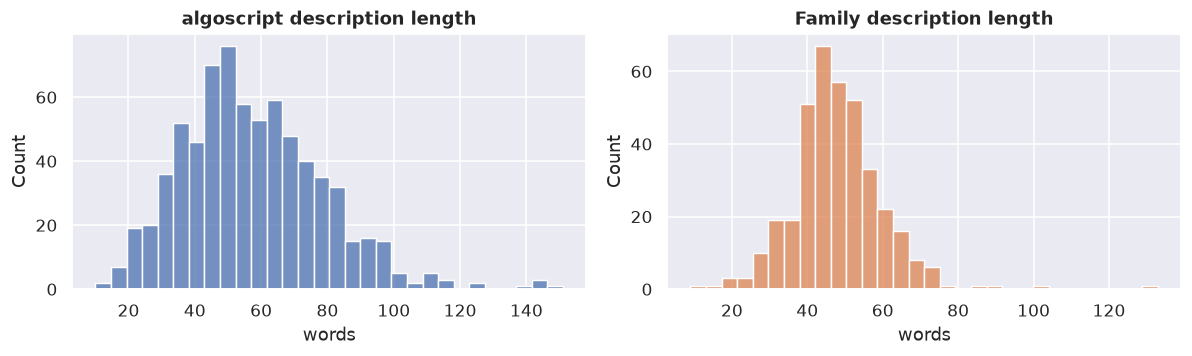

In [6]:
desc = df[["n_words", "fam_n_words"]].describe(
    percentiles=[.05, .5, .95]).T.round(1)
desc.index = ["algoscript description (words)", "family description (words)"]
display(desc)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
sns.histplot(df.n_words, bins=30, ax=ax[0], color="#4C72B0")
ax[0].set_title("algoscript description length")
ax[0].set_xlabel("words")
sns.histplot(fam.description.str.split().str.len(),
             bins=30, ax=ax[1], color="#DD8452")
ax[1].set_title("Family description length")
ax[1].set_xlabel("words")
finish(fig, "01_text_lengths")

,value
algoscripts,721
Result families,373
Subjects,17
algoscripts per family (mean),1.93
Families with ≥2 algoscripts,168 (45.0%)
algoscripts living in a multi-algoscript family,71.6%
Distinct primary MSC codes,252
Distinct primary MSC sections,40
Families with a Lean formalisation link,245 (65.7%)
Release span,"Sep 10 → Oct 25, 2026"


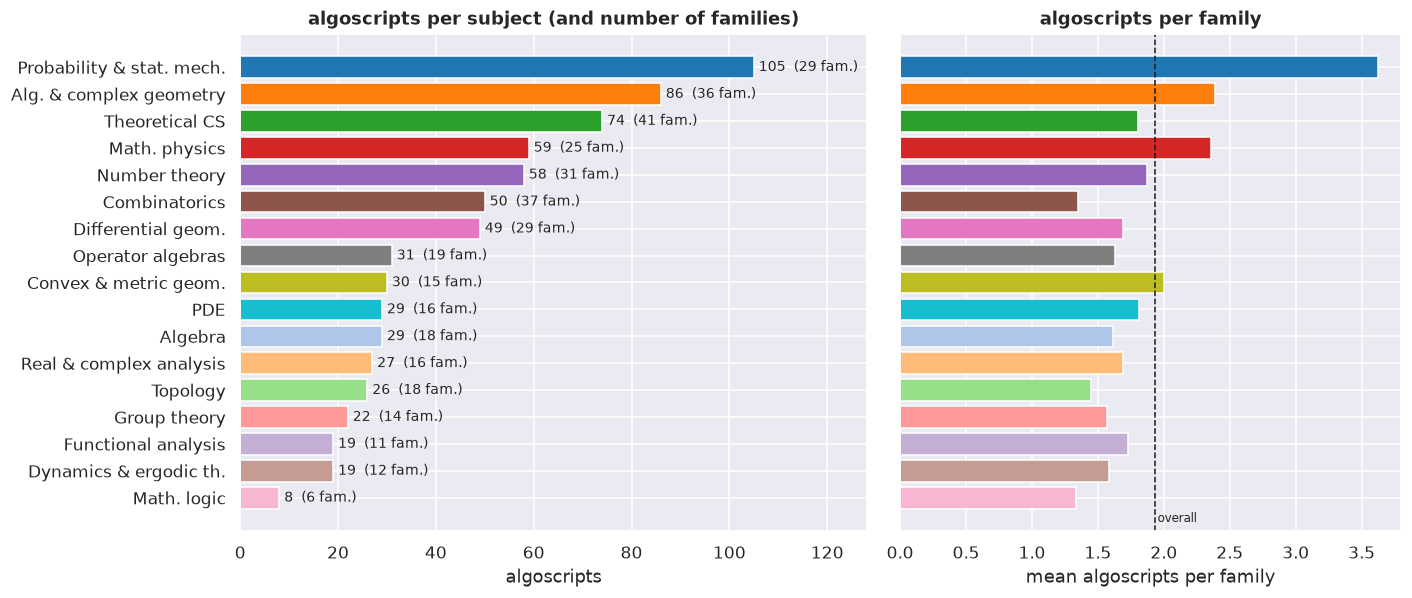

> **Takeaway.** **Probability & stat. mech.** is the largest subject (105 algoscripts, 14.6%), **Math. logic** the smallest (8, 1.1%). Documentation intensity differs: the mean family has 1.93 algoscripts overall, from 1.33 (*Math. logic*) up to 3.62 (*Probability & stat. mech.*).

In [7]:
subj = (df.groupby("subject").agg(algoscripts=("paper_name", "size"), families=("result_family_number", "nunique"))
          .assign(per_family=lambda d: d.algoscripts / d.families, share=lambda d: d.algoscripts / d.algoscripts.sum())
          .sort_values("algoscripts", ascending=False))
SUBJECTS = subj.index.tolist()
_t20 = sns.color_palette("tab20", 20)
# saturated colours first ...
_idx = list(range(0, 20, 2)) + list(range(1, 20, 2))
# ... so the biggest subjects get them
PAL = {s: _t20[_idx[i]] for i, s in enumerate(SUBJECTS)}
# marker shape as 2nd visual channel
MARK = {s: "osD^vPXp*<>h8dHo"[i % 16] for i, s in enumerate(SUBJECTS)}

kpi = pd.Series({"algoscripts": len(df), "Result families": len(fam), "Subjects": len(SUBJECTS),
                 "algoscripts per family (mean)": round(len(df) / len(fam), 2),
                 "Families with ≥2 algoscripts": f"{(fam.n_papers >= 2).sum()} ({pct((fam.n_papers >= 2).mean())})",
                 "algoscripts living in a multi-algoscript family": pct(df.result_family_number.map(fam.set_index('family').n_papers).gt(1).mean()),
                 "Distinct primary MSC codes": fam.msc_primary.nunique(), "Distinct primary MSC sections": fam.msc_section.nunique(),
                 "Families with a Lean formalisation link": f"{fam.has_lean.sum()} ({pct(fam.has_lean.mean())})",
                 "Release span": f"{df.release.min():%b %d} → {df.release.max():%b %d, %Y}"}, name="value").to_frame()
display(kpi)

fig, ax = plt.subplots(1, 2, figsize=(13, 5.6), gridspec_kw={
                       "width_ratios": [1.25, 1]})
order = subj.index[::-1]
ax[0].barh(order, subj.loc[order, "algoscripts"], color=[PAL[s]
           for s in order])
for y, (m, f) in enumerate(zip(subj.loc[order, "algoscripts"], subj.loc[order, "families"])):
    ax[0].text(m + 1, y, f"{m}  ({f} fam.)", va="center", fontsize=9)
ax[0].set_title("algoscripts per subject (and number of families)")
ax[0].set_xlabel("algoscripts")
ax[0].set_xlim(0, subj.algoscripts.max() * 1.22)
ax[1].barh(order, subj.loc[order, "per_family"], color=[PAL[s] for s in order])
ax[1].axvline(len(df) / len(fam), color="k", ls="--", lw=1)
ax[1].text(len(df) / len(fam) + .02, -0.9, "overall", fontsize=8)
ax[1].set_yticklabels([])
ax[1].set_title("algoscripts per family")
ax[1].set_xlabel("mean algoscripts per family")
finish(fig, "02_subject_sizes")
big, small = subj.iloc[0], subj.iloc[-1]
takeaway(f"**{subj.index[0]}** is the largest subject ({int(big.algoscripts)} algoscripts, {pct(big.share)}), **{subj.index[-1]}** the smallest "
         f"({int(small.algoscripts)}, {pct(small.share)}). Documentation intensity differs: the mean family has {len(df) / len(fam):.2f} algoscripts overall, "
         f"from {subj.per_family.min():.2f} (*{subj.per_family.idxmin()}*) up to {subj.per_family.max():.2f} (*{subj.per_family.idxmax()}*).")

**How to read it.** (above) A subject with many algoscripts per family is one where results are documented through several companion algoscripts
(e.g. separate papers for sub-cases, strengthenings or formalisations); a subject with ≈ 1 is made of stand-alone papers.

Gini coefficient / Lorenz curve: 0 = every family has the same number of algoscripts, 1 = all algoscripts sit in one family

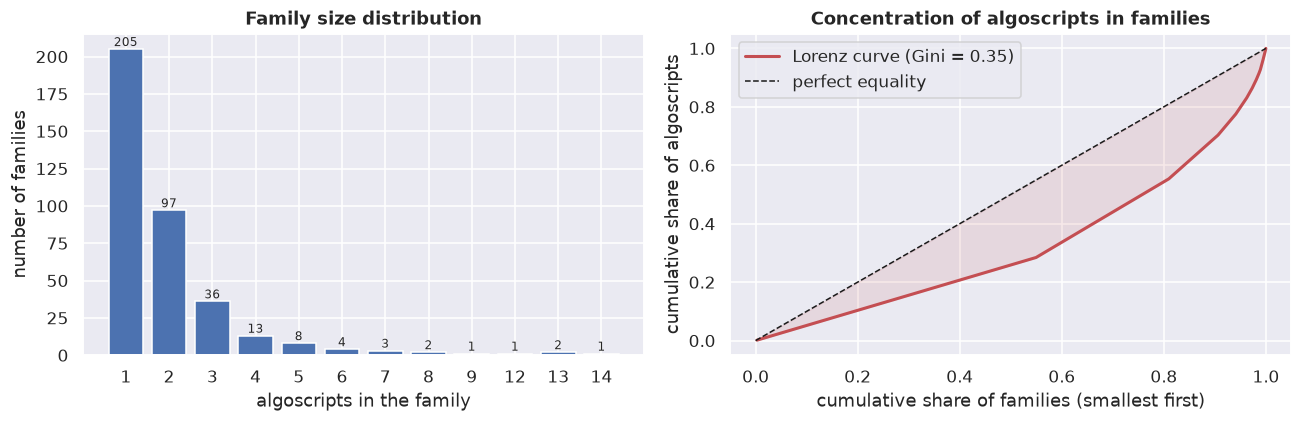

,family,title,subject,algoscripts
0,34,Log abundance for compact Kähler spaces under logarithmic Iitaka subadditivity,Alg. & complex geometry,14
1,237,The three-quarter exponent for honeycomb self-avoiding walk,Probability & stat. mech.,13
2,260,"Spacetime Penrose inequalities: enclosing area, charge, rotation, and anti-de Sitter extensions",Math. physics,13
3,238,Optimal logarithmic mixing of the Thorp shuffle,Probability & stat. mech.,12
4,376,Universal computation in forced Navier–Stokes flows,PDE,9
5,14,"Restricted geometric Langlands, global Arthur enhancements, and generic Ramanujan",Number theory,8
6,227,Critical SK autocorrelation processes and dynamics across the temperature transition,Probability & stat. mech.,8
7,68,Anticanonical nonvanishing in every dimension,Alg. & complex geometry,7
8,211,"The geometric phase diagram, diffusion, and spectra of random planar maps",Probability & stat. mech.,7
9,331,Reflexive midpoint convexity and diamond distortion,Functional analysis,7


> **Takeaway.** 55.0% of families rest on a single algoscript, yet the ten largest families alone contain 13.6% of all algoscripts (Gini = 0.35). The largest family, #034, has 14 algoscripts.

In [8]:
def gini(x):
    x = np.sort(np.asarray(x, float))
    n = len(x)
    return (2 * np.sum(np.arange(1, n + 1) * x) / (n * x.sum())) - (n + 1) / n


size_dist = fam.n_papers.value_counts().sort_index()
lor = np.cumsum(np.sort(fam.n_papers.values)) / fam.n_papers.sum()
xs = np.arange(1, len(lor) + 1) / len(lor)
GINI = gini(fam.n_papers)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
bars = ax[0].bar(size_dist.index.astype(
    str), size_dist.values, color="#4C72B0")
for b, v in zip(bars, size_dist.values):
    ax[0].text(b.get_x() + b.get_width() / 2, v +
               2, str(v), ha="center", fontsize=8)
ax[0].set_xlabel("algoscripts in the family")
ax[0].set_ylabel("number of families")
ax[0].set_title("Family size distribution")
ax[1].plot(xs, lor, color="#C44E52", lw=2,
           label=f"Lorenz curve (Gini = {GINI:.2f})")
ax[1].plot([0, 1], [0, 1], "k--", lw=1, label="perfect equality")
ax[1].fill_between(xs, lor, xs, color="#C44E52", alpha=.12)
ax[1].set_xlabel("cumulative share of families (smallest first)")
ax[1].set_ylabel("cumulative share of algoscripts")
ax[1].set_title("Concentration of algoscripts in families")
ax[1].legend(loc="upper left")
finish(fig, "03_family_sizes")

top = fam.sort_values(["n_papers", "family"], ascending=[False, True]).head(10)[
    ["family", "title", "subject", "n_papers"]]
display(top.rename(columns={"n_papers": "algoscripts"}).reset_index(drop=True))
top10_share = fam.n_papers.nlargest(10).sum() / fam.n_papers.sum()
takeaway(f"{pct((fam.n_papers == 1).mean())} of families rest on a single algoscript, yet the ten largest families alone contain {pct(top10_share)} of all algoscripts "
         f"(Gini = {GINI:.2f}). The largest family, #{top.iloc[0].family:03d}, has {top.iloc[0].n_papers} algoscripts.")

## Release timeline

**What we compute.** algoscript counts per release day, the cumulative curve, and which subjects appeared when. Because releases come in bursts we define five *batches* from the observed histogram (edit `bins` if re-run on other data).

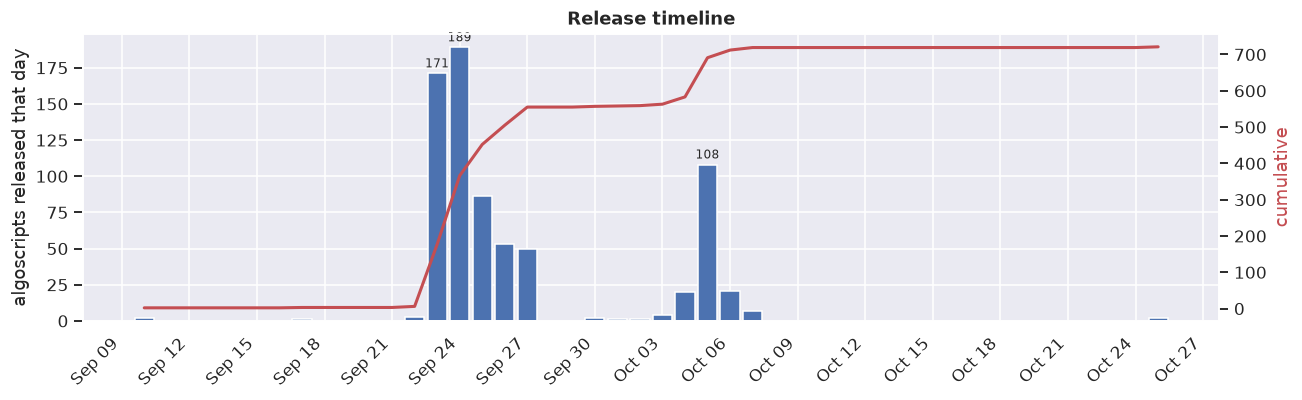

,algoscripts,share
batch,,
Early (≤ Sep 21),3,0.4%
Batch 1 (Sep 22–27),552,76.6%
Interlude (Sep 28–Oct 3),8,1.1%
Batch 2 (Oct 4–7),156,21.6%
Late (≥ Oct 8),2,0.3%


> **Takeaway.** Two bursts dominate the catalog: **Batch 1 (Sep 22–27)** brings 76.6% of all algoscripts and **Batch 2 (Oct 4–7)** a further 21.6%; the busiest single day has 189 algoscripts (Sep 24).

In [9]:
daily = df.groupby("release").size()
full = daily.reindex(pd.date_range(
    daily.index.min(), daily.index.max()), fill_value=0)

fig, ax = plt.subplots(figsize=(12, 3.8))
ax.bar(full.index, full.values, color="#4C72B0", width=.85)
ax.set_ylabel("algoscripts released that day")
ax.set_title("Release timeline")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
ax.xaxis.set_major_locator(mdates.DayLocator(interval=3))
plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
ax2 = ax.twinx()
ax2.plot(full.index, full.cumsum(), color="#C44E52", lw=2)
ax2.set_ylabel("cumulative", color="#C44E52")
ax2.grid(False)
ax2.spines["right"].set_visible(True)
for d, v in daily.nlargest(3).items():
    ax.annotate(f"{v}", (d, v), textcoords="offset points",
                xytext=(0, 4), ha="center", fontsize=8)
finish(fig, "04_timeline")

bins = pd.to_datetime(["2000-01-01", "2026-09-21",
                      "2026-09-27", "2026-10-03", "2026-10-07", "2100-01-01"])
labels = ["Early (≤ Sep 21)", "Batch 1 (Sep 22–27)",
          "Interlude (Sep 28–Oct 3)", "Batch 2 (Oct 4–7)", "Late (≥ Oct 8)"]
df["batch"] = pd.cut(df.release, bins=bins, labels=labels)
display(df.batch.value_counts().reindex(labels).to_frame("algoscripts").assign(
    share=lambda d: (d.algoscripts / d.algoscripts.sum()).map(pct)))
share_b1 = (df.batch == labels[1]).mean()
share_b2 = (df.batch == labels[3]).mean()
takeaway(f"Two bursts dominate the catalog: **{labels[1]}** brings {pct(share_b1)} of all algoscripts and **{labels[3]}** a further {pct(share_b2)}; "
         f"the busiest single day has {daily.max()} algoscripts ({daily.idxmax():%b %d}).")

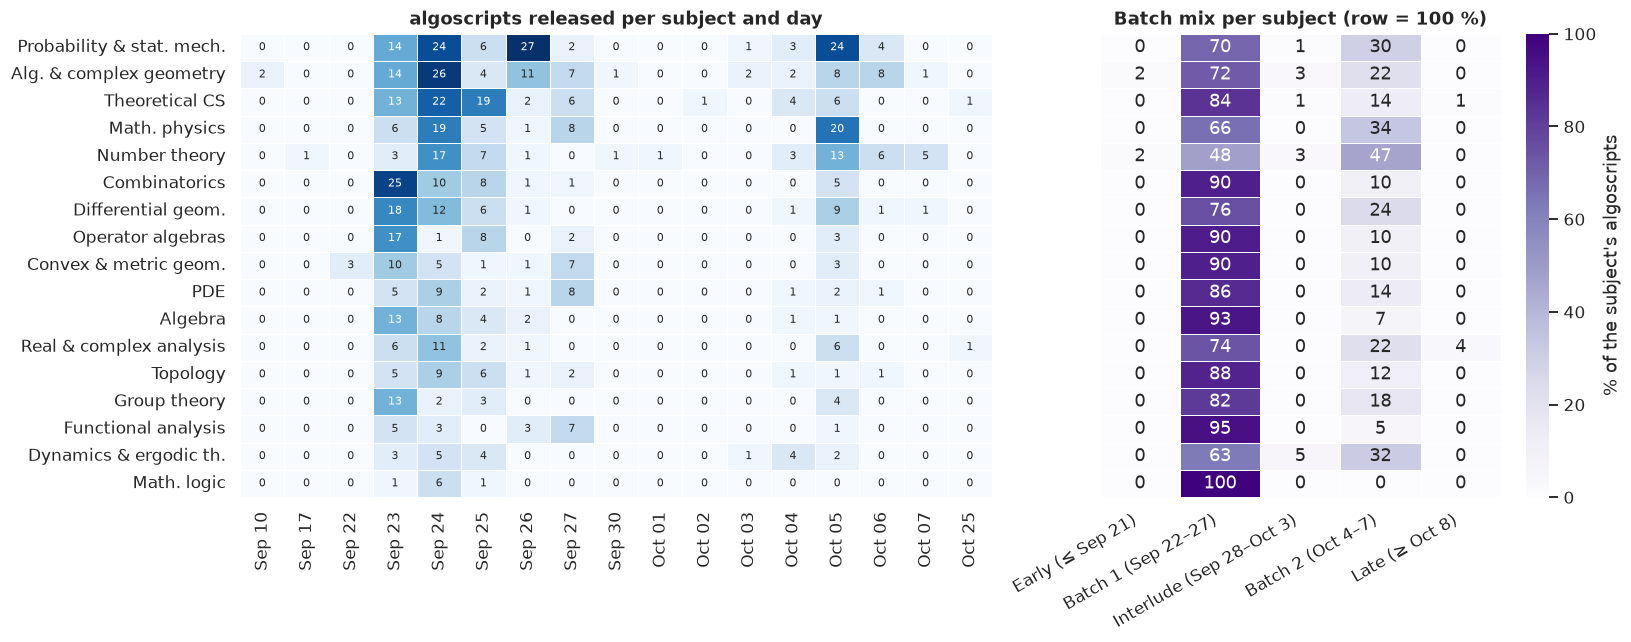

> **Takeaway.** Most subjects were released predominantly in one batch (median dominant-batch share 84 %). The subjects most skewed to *Batch 2 (Oct 4–7)* are **Number theory, Math. physics, Dynamics & ergodic th.** (47 %, 34 %, 32 %).

In [10]:
heat = pd.crosstab(df.subject, df.release).reindex(SUBJECTS)
heat.columns = [f"{c:%b %d}" for c in heat.columns]
bshare = pd.crosstab(df.subject, df.batch,
                     normalize="index").reindex(SUBJECTS) * 100

fig, ax = plt.subplots(1, 2, figsize=(15, 6), gridspec_kw={
                       "width_ratios": [1.5, 1]})
sns.heatmap(heat, annot=True, fmt="d", cmap="Blues", cbar=False,
            linewidths=.4, annot_kws={"fontsize": 7}, ax=ax[0])
ax[0].set_title("algoscripts released per subject and day")
ax[0].set_xlabel("")
ax[0].set_ylabel("")
sns.heatmap(bshare, annot=True, fmt=".0f", cmap="Purples", vmin=0, vmax=100,
            linewidths=.4, cbar_kws={"label": "% of the subject's algoscripts"}, ax=ax[1])
ax[1].set_title("Batch mix per subject (row = 100 %)")
ax[1].set_ylabel("")
ax[1].set_xlabel("")
ax[1].set_yticklabels([])
plt.setp(ax[1].get_xticklabels(), rotation=30, ha="right")
finish(fig, "05_release_heatmaps")

dom = bshare.idxmax(axis=1)
domshare = bshare.max(axis=1)
b2_heavy = bshare[labels[3]].sort_values(ascending=False)
takeaway(f"Most subjects were released predominantly in one batch (median dominant-batch share {domshare.median():.0f} %). "
         f"The subjects most skewed to *{labels[3]}* are **{', '.join(b2_heavy.index[:3])}** ({', '.join(f'{v:.0f} %' for v in b2_heavy.values[:3])}).")

**How to read it.** The heatmap shows *how many algoscripts of each subject were released on each day*; the batch table shows each subject's **row-normalised** mix (every row sums to 100 %).

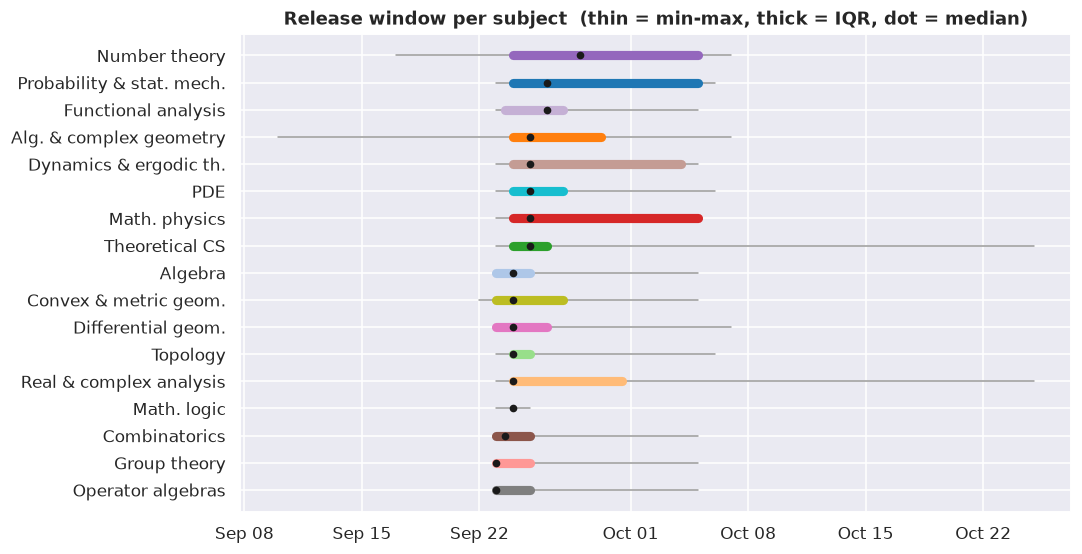

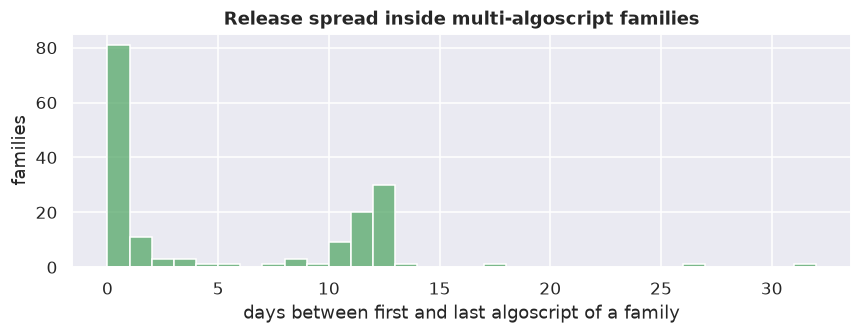

> **Takeaway.** Among the 168 multi-algoscript families, 48.2% were released entirely on one day; the others trickled in over up to 31 days (median 1).

In [11]:
# When did each subject appear?  (min / IQR / max of release dates, ordered by median)
q = df.groupby("subject").release.agg(
    ["min", lambda s: s.quantile(.25), "median", lambda s: s.quantile(.75), "max"])
q.columns = ["min", "q1", "median", "q3", "max"]
q = q.sort_values("median")
fig, ax = plt.subplots(figsize=(10, 5.2))
for y, (s, r) in enumerate(q.iterrows()):
    ax.plot([r["min"], r["max"]], [y, y], color="#999", lw=1)
    ax.plot([r["q1"], r["q3"]], [y, y], color=PAL[s],
            lw=6, solid_capstyle="round")
    ax.plot(r["median"], y, "o", color="k", ms=4)
ax.set_yticks(range(len(q)))
ax.set_yticklabels(q.index)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
ax.set_title(
    "Release window per subject  (thin = min-max, thick = IQR, dot = median)")
finish(fig, "06_release_windows")

# Families whose algoscripts were released on different days
multi = fam[fam.n_papers > 1].assign(
    span_days=lambda d: (d.last_release - d.first_release).dt.days)
fig, ax = plt.subplots(figsize=(8, 3.2))
sns.histplot(multi.span_days, bins=range(
    0, int(multi.span_days.max()) + 2), ax=ax, color="#55A868")
ax.set_xlabel("days between first and last algoscript of a family")
ax.set_ylabel("families")
ax.set_title("Release spread inside multi-algoscript families")
finish(fig, "07_family_span")
takeaway(f"Among the {len(multi)} multi-algoscript families, {pct((multi.span_days == 0).mean())} were released entirely on one day; the others trickled in over up to {multi.span_days.max()} days "
         f"(median {multi.span_days.median():.0f}).")

## Anatomy of a result

The catalog is dominated by *headline claims*. To see **which kinds of claims** it contains, we tag each family (title + description) with six non-exclusive
labels using regular expressions:

| Tag | Intent |
|---|---|
| Mentions a named conjecture/problem | the title or statement refers to a conjecture, problem, question or hypothesis (usually: *resolves* it) |
| Disproof / counterexample / negative | counterexamples, "disproves", failures, impossibility / negative answers, undecidability |
| Sharp / optimal / asymptotic | sharp or optimal constants, exact thresholds, matching bounds, exponents |
| Classification / characterisation | classifies, characterises, determines |
| Algorithm / complexity | algorithms, running times, hardness, circuit/complexity bounds |
| Explicit construction | "constructs …", explicit examples |

- > ⚠️ Regex tagging is a *heuristic*: it is deterministic and inspectable (see `FLAGS`), but it will mis-tag some families. Use the numbers as indicative shares.

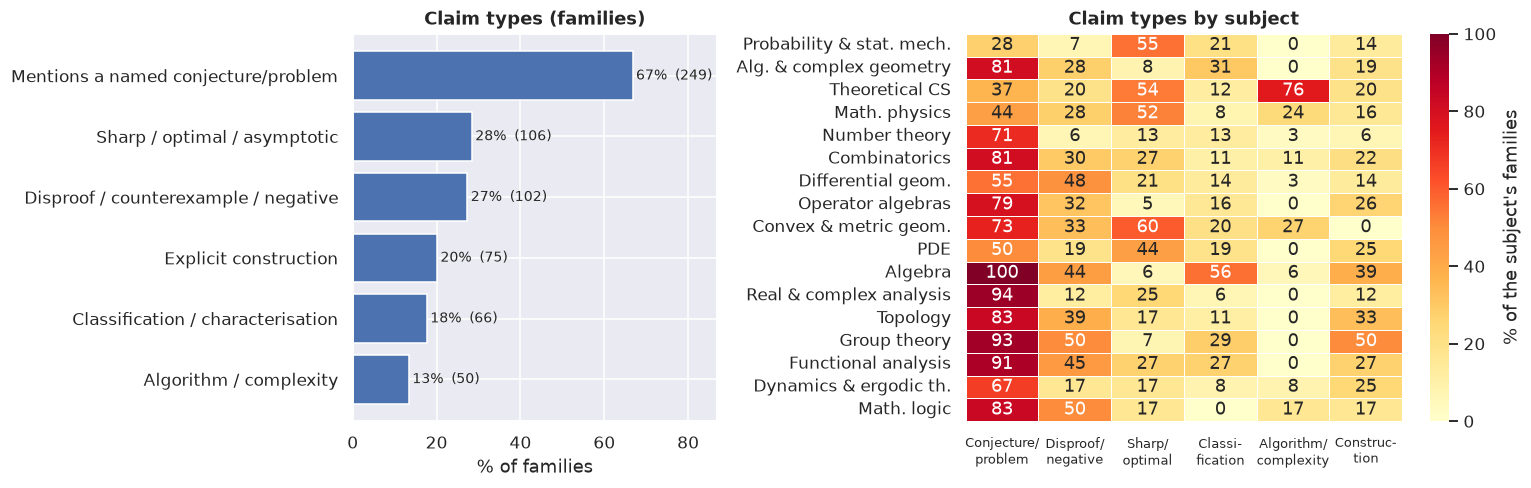

> **Takeaway.** The most common claim type is **mentions a named conjecture/problem** (67% of families). Negative/disproof-type results are most frequent in **Math. logic** (50% of its families) and least in **Number theory** (6%). On average a family carries 1.7 of the 6 tags; 6% carry none.

In [12]:
FLAGS = {
    "Mentions a named conjecture/problem": r"conjecture|\bproblem\b|\bquestion\b|\bhypothesis\b",
    "Disproof / counterexample / negative": r"counterexample|disprov|negative(?:ly)?\b|\bfail(?:s|ure|ed)?\b|\bcannot\b|\bdoes not\b|\bdo not\b|nonexistence|undecidab|nonuniqueness|nonattainment|no (?:algorithm|bigeodesic|local|proper)",
    "Sharp / optimal / asymptotic":        r"\bsharp\b|\boptimal|\bexact\b|\btight\b|asymptotic|\bexponent|threshold|matching (?:lower|upper)|Θ",
    "Classification / characterisation":   r"classif|characteri[sz]|\bdetermines?\b|\bidentifie",
    "Algorithm / complexity":              r"algorithm|polynomial[- ]time|\bfpras\b|approximation scheme|np-hard|quasipolynomial|\bcircuit|complexity|hardness|lower bound",
    "Explicit construction":               r"\bconstructs?\b|\bconstruction\b|\bexplicit(?:ly)?\b",
}
text = (fam.title + " " + fam.description).str.lower()
for name, rx in FLAGS.items():
    fam[name] = text.str.contains(rx, regex=True)
FLAG_COLS = list(FLAGS)
FLAG_SHORT = ["Conjecture/\nproblem", "Disproof/\nnegative", "Sharp/\noptimal",
              "Classi-\nfication", "Algorithm/\ncomplexity", "Construc-\ntion"]
fam["n_flags"] = fam[FLAG_COLS].sum(axis=1)

overall = fam[FLAG_COLS].mean().sort_values()
fig, ax = plt.subplots(1, 2, figsize=(14, 4.6), gridspec_kw={
                       "width_ratios": [1, 1.5]})
ax[0].barh(overall.index, overall.values * 100, color="#4C72B0")
for y, v in enumerate(overall.values):
    ax[0].text(v * 100 + .8, y,
               f"{v*100:.0f}%  ({int(v*len(fam))})", va="center", fontsize=9)
ax[0].set_xlim(0, overall.max() * 100 * 1.3)
ax[0].set_xlabel("% of families")
ax[0].set_title("Claim types (families)")

mat = fam.groupby("subject")[FLAG_COLS].mean().reindex(SUBJECTS) * 100
sns.heatmap(mat, annot=True, fmt=".0f", cmap="YlOrRd", linewidths=.4,
            cbar_kws={"label": "% of the subject's families"}, ax=ax[1])
ax[1].set_title("Claim types by subject")
ax[1].set_ylabel("")
ax[1].set_xticklabels(FLAG_SHORT, rotation=0, fontsize=8.5)
finish(fig, "08_claim_types")

cx = fam.groupby("subject").agg(n=("family", "size"), counter=(
    "Disproof / counterexample / negative", "sum"))
cx["share"] = cx.counter / cx.n
cx = cx[cx.n >= 5].sort_values("share", ascending=False)
takeaway(f"The most common claim type is **{overall.index[-1].lower()}** ({pct(overall.iloc[-1], 0)} of families). "
         f"Negative/disproof-type results are most frequent in **{cx.index[0]}** ({pct(cx.share.iloc[0], 0)} of its families) and least in **{cx.index[-1]}** ({pct(cx.share.iloc[-1], 0)}). "
         f"On average a family carries {fam.n_flags.mean():.1f} of the 6 tags; {pct((fam.n_flags == 0).mean(), 0)} carry none.")

In [13]:
# Examples per tag (random but reproducible), to sanity-check the regex tagging
rng = np.random.default_rng(SEED)
for name in ["Disproof / counterexample / negative", "Algorithm / complexity", "Classification / characterisation"]:
    sample = fam[fam[name]].sample(6, random_state=SEED)[
        ["family", "subject", "title"]]
    display(
        Markdown(f"**{name}** - {int(fam[name].sum())} families, random sample:"))
    display(sample.reset_index(drop=True))

**Disproof / counterexample / negative** - 102 families, random sample:

,family,subject,title
0,156,Combinatorics,Borsuk's conjecture fails in dimension nine
1,285,Operator algebras,Counterexamples to Baum–Connes and Kadison–Kaplansky
2,271,Math. physics,"Bloch's law, its lattice correction, and the spherical magnetization law"
3,209,Algebra,Integral counterexamples to Gersten’s conjecture
4,197,Algebra,A torsion-free group algebra that is not directly finite
5,195,Algebra,A counterexample to the small Cohen–Macaulay module conjecture


**Algorithm / complexity** - 50 families, random sample:

,family,subject,title
0,113,Theoretical CS,Approximate counting and entropy of perfect matchings
1,191,Combinatorics,A power improvement in the Heilbronn triangle lower bound
2,138,Theoretical CS,Subset Sum in O(2^(0.49n)) time
3,279,Math. physics,Exact quantum factoring over a fixed finite gate set
4,118,Theoretical CS,Bin packing and unbounded configuration-LP gaps
5,347,Differential geom.,Counterexamples to stable-Morse and strong Arnold fixed-point bounds


**Classification / characterisation** - 66 families, random sample:

,family,subject,title
0,305,Topology,Four-dimensional disk embedding and Wall's conjecture
1,356,Differential geom.,Gigli’s characterization of Alexandrov curvature
2,1,Number theory,Milne’s rationality conjecture and algebraic specialization
3,249,Group theory,A finitely generated Eilenberg–Ganea counterexample
4,34,Alg. & complex geometry,Log abundance for compact Kähler spaces under logarithmic Iitaka subadditivity
5,365,PDE,Joint metric and connection recovery from one boundary patch


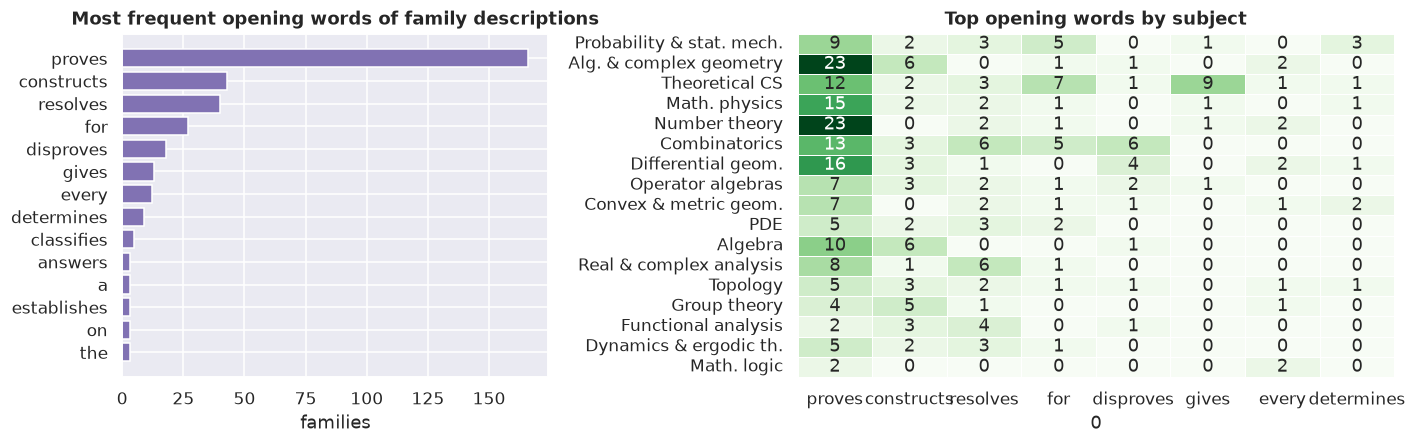

> **Takeaway.** 'Proves' opens 45% of the family descriptions. Verbs of construction and disproof (*constructs*, *disproves*) open 16%.

**100 families (26.8%) carry a conjecture / problem / question in their title.** Share by subject:

subject,Algebra,Topology,PDE,Dynamics & ergodic th.,Real & complex analysis,Functional analysis,Alg. & complex geometry,Combinatorics,Number theory,Operator algebras,Convex & metric geom.,Differential geom.,Group theory,Theoretical CS,Math. physics,Probability & stat. mech.,Math. logic
families,12,9,7,5,6,4,12,12,10,6,4,7,2,2,1,1,0
share,66.7%,50.0%,43.8%,41.7%,37.5%,36.4%,33.3%,32.4%,32.3%,31.6%,26.7%,24.1%,14.3%,4.9%,4.0%,3.4%,0.0%


In [14]:
# How do descriptions *start*?  The opening verb signals the nature of the claim ("Proves", "Constructs", "Disproves" ...).
first = fam.description.str.extract(r"^([A-Za-zÀ-ÿ’'-]+)")[0].str.lower()
top_first = first.value_counts().head(14)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw={
                       "width_ratios": [1, 1.4]})
ax[0].barh(top_first.index[::-1], top_first.values[::-1], color="#8172B3")
ax[0].set_title("Most frequent opening words of family descriptions")
ax[0].set_xlabel("families")
ct = pd.crosstab(fam.subject, first)[top_first.index[:8]].reindex(SUBJECTS)
sns.heatmap(ct, annot=True, fmt="d", cmap="Greens",
            cbar=False, linewidths=.4, ax=ax[1])
ax[1].set_title("Top opening words by subject")
ax[1].set_ylabel("")
finish(fig, "09_opening_words")
pr = (first == "proves").mean()
takeaway(f"'{top_first.index[0].capitalize()}' opens {pct(top_first.iloc[0] / len(fam), 0)} of the family descriptions. Verbs of construction and disproof "
         f"(*constructs*, *disproves*) open {pct(first.isin(['constructs', 'disproves']).mean(), 0)}.")

# Families named after a conjecture / problem
named = fam.title.str.contains(r"conjecture|problem|question", case=False)
ns = fam.assign(named=named).groupby("subject").named.agg(
    ["sum", "mean"]).sort_values("mean", ascending=False)
display(Markdown(
    f"**{named.sum()} families ({pct(named.mean())}) carry a conjecture / problem / question in their title.** Share by subject:"))
display(ns.rename(columns={"sum": "families", "mean": "share"}).assign(
    share=lambda d: d.share.map(pct)).T)

## Mathematics Subject Classification

The [MSC](https://msc2020.org/) is the standard taxonomy used by *zbMATH* and *MathSciNet*. A code like `11G40` = section **11** (Number theory) → subsection **11G** →
topic **11G40** (L-functions of varieties over global fields; Birch–Swinnerton-Dyer). Each family has one primary code and 0-3 secondary codes.

Things we look at:
1. Distribution over MSC sections (family level).
2. How well the catalog's own `main_subject` aligns with MSC (entropy, purity, Cramér's V).
3. **Interdisciplinarity**: how many distinct MSC sections a result touches.
4. A **network of MSC sections** linked when they co-occur in the same family, this reveals the *bridges* between fields.

> The codes are a curated classification not mentioned in the papers, this section analyses that additional classification.

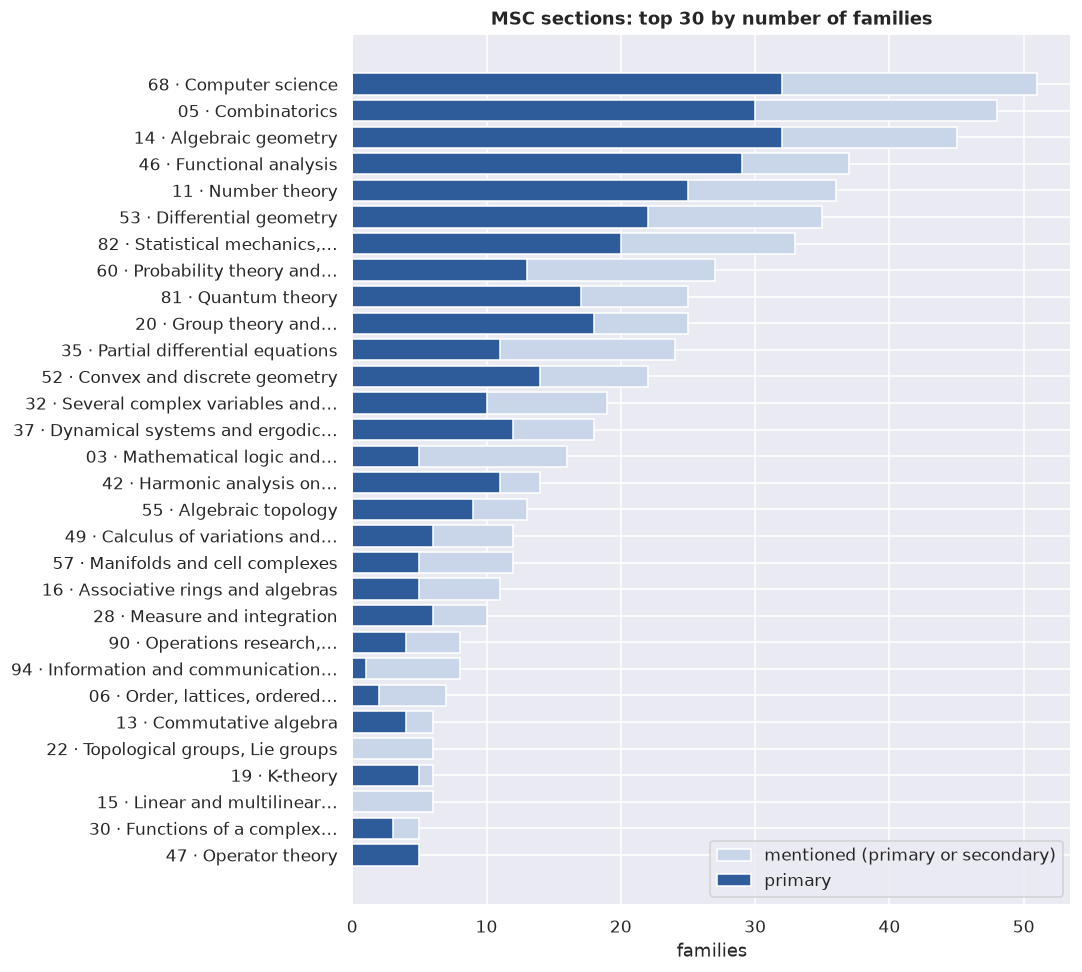

> **Takeaway.** 40 distinct MSC sections serve as primary classification; the three biggest are Algebraic geometry (32), Computer science (32), Combinatorics (30). 51 sections are touched when secondary codes are included.

**Most frequent primary 5-character codes**

,families,algoscripts,section
MSC code,,,
82B20,9,30,"Statistical mechanics, structure of matter"
14E30,5,27,Algebraic geometry
68Q17,5,10,Computer science
68Q25,5,8,Computer science
52C10,5,6,Convex and discrete geometry
05D10,5,6,Combinatorics
81P68,5,8,Quantum theory
46L10,5,9,Functional analysis
46B85,4,7,Functional analysis


In [15]:
MSC_NAMES = {"00": "General and overarching topics", "01": "History and biography", "03": "Mathematical logic and foundations", "05": "Combinatorics",
             "06": "Order, lattices, ordered algebraic structures", "08": "General algebraic systems", "11": "Number theory", "12": "Field theory and polynomials",
             "13": "Commutative algebra", "14": "Algebraic geometry", "15": "Linear and multilinear algebra; matrix theory", "16": "Associative rings and algebras",
             "17": "Nonassociative rings and algebras", "18": "Category theory; homological algebra", "19": "K-theory", "20": "Group theory and generalizations",
             "22": "Topological groups, Lie groups", "26": "Real functions", "28": "Measure and integration", "30": "Functions of a complex variable", "31": "Potential theory",
             "32": "Several complex variables and analytic spaces", "33": "Special functions", "34": "Ordinary differential equations", "35": "Partial differential equations",
             "37": "Dynamical systems and ergodic theory", "39": "Difference and functional equations", "40": "Sequences, series, summability", "41": "Approximations and expansions",
             "42": "Harmonic analysis on Euclidean spaces", "43": "Abstract harmonic analysis", "44": "Integral transforms, operational calculus", "45": "Integral equations",
             "46": "Functional analysis", "47": "Operator theory", "49": "Calculus of variations and optimal control; optimization", "51": "Geometry", "52": "Convex and discrete geometry",
             "53": "Differential geometry", "54": "General topology", "55": "Algebraic topology", "57": "Manifolds and cell complexes", "58": "Global analysis, analysis on manifolds",
             "60": "Probability theory and stochastic processes", "62": "Statistics", "65": "Numerical analysis", "68": "Computer science", "70": "Mechanics of particles and systems",
             "74": "Mechanics of deformable solids", "76": "Fluid mechanics", "78": "Optics, electromagnetic theory", "80": "Classical thermodynamics, heat transfer", "81": "Quantum theory",
             "82": "Statistical mechanics, structure of matter", "83": "Relativity and gravitational theory", "85": "Astronomy and astrophysics", "86": "Geophysics",
             "90": "Operations research, mathematical programming", "91": "Game theory, economics, social and behavioral sciences", "92": "Biology and other natural sciences",
             "93": "Systems theory; control", "94": "Information and communication theory, circuits", "97": "Mathematics education"}


def sec_label(c, w=30): return f"{c} · " + textwrap.shorten(
    MSC_NAMES.get(c, "?"), width=w, placeholder="…")


sec_counts = fam.msc_section.value_counts()
# sections mentioned in ANY role
n_all = Counter(s for l in fam.msc_sections_all for s in l)
cmp_ = pd.DataFrame({"primary": sec_counts, "any_role": pd.Series(n_all)}).fillna(
    0).astype(int).sort_values("any_role", ascending=False)

fig, ax = plt.subplots(figsize=(10, 9))
d = cmp_.head(30)[::-1]
ax.barh([sec_label(c) for c in d.index], d.any_role,
        color="#C9D6EA", label="mentioned (primary or secondary)")
ax.barh([sec_label(c) for c in d.index], d.primary,
        color="#2E5C9A", label="primary")
ax.set_xlabel("families")
ax.set_title("MSC sections: top 30 by number of families")
ax.legend(loc="lower right")
finish(fig, "10_msc_sections")
top3 = ", ".join(f"{MSC_NAMES[c]} ({n})" for c,
                 n in sec_counts.head(3).items())
takeaway(f"{fam.msc_section.nunique()} distinct MSC sections serve as primary classification; the three biggest are {top3}. "
         f"{len(n_all)} sections are touched when secondary codes are included.")

codes = (fam.msc_primary.value_counts().head(15).rename_axis("MSC code").to_frame("families")
         .assign(algoscripts=lambda d: [int(df.msc_primary.eq(c).sum()) for c in d.index],
                 section=lambda d: [MSC_NAMES[c[:2]] for c in d.index]))
display(Markdown("**Most frequent primary 5-character codes**"))
display(codes)

,families,distinct_sections,modal_section,modal_share,entropy_bits
subject,,,,,
Probability & stat. mech.,29,4,"82 Statistical mechanics, s",55.2%,1.34
Alg. & complex geometry,36,4,14 Algebraic geometry,72.2%,1.11
Theoretical CS,41,9,68 Computer science,73.2%,1.60
Math. physics,25,6,81 Quantum theory,68.0%,1.59
Number theory,31,5,11 Number theory,71.0%,1.29
Combinatorics,37,5,05 Combinatorics,73.0%,1.27
Differential geom.,29,6,53 Differential geometry,72.4%,1.44
Operator algebras,19,3,46 Functional analysis,89.5%,0.59
Convex & metric geom.,15,6,52 Convex and discrete geom,53.3%,1.99


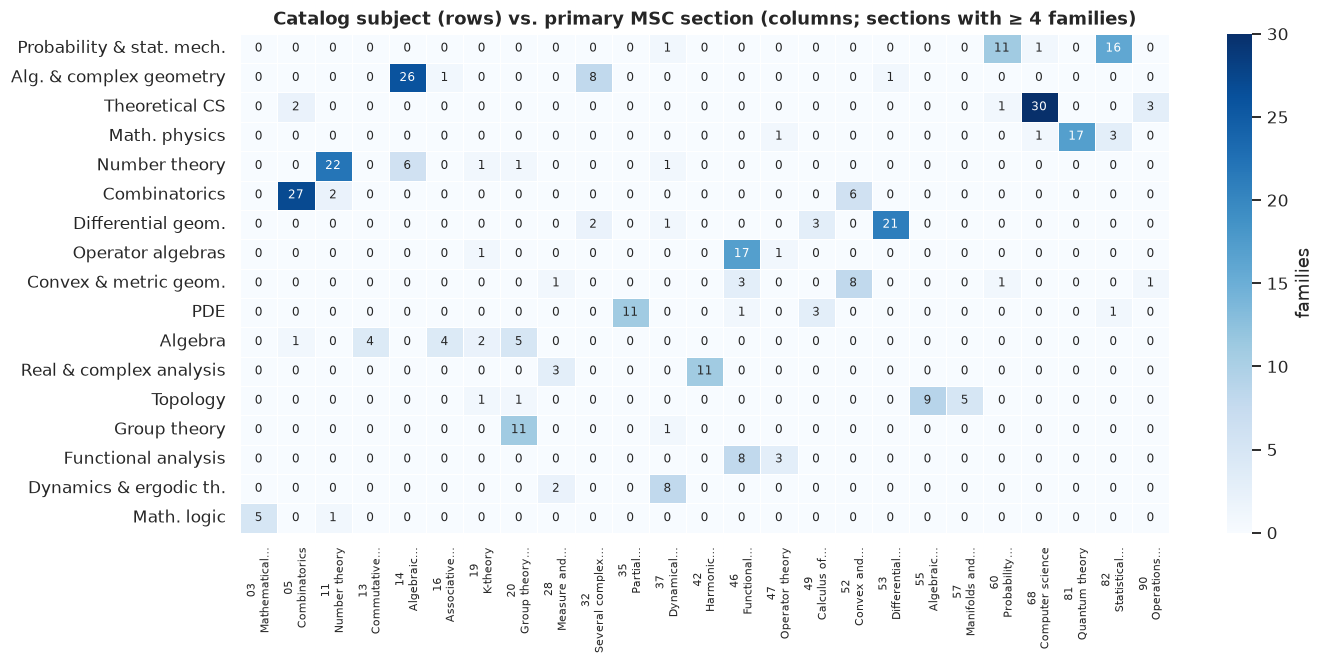

> **Takeaway.** Subject and MSC are strongly associated (Cramér's V = 0.83, NMI = 0.76) but far from identical. **Algebra** is the most *heterogeneous* subject (2.5 bits across 7 MSC sections), **Operator algebras** the most *focused* (0.6 bits; 89% in a single section).

In [16]:
# --- Alignment between the catalog's subject and the MSC section ---------------------------------
ct = pd.crosstab(fam.subject, fam.msc_section)
chi2, p, dof, _ = chi2_contingency(ct)
cramers_v = math.sqrt((chi2 / ct.values.sum()) / (min(ct.shape) - 1))
nmi_subj_msc = normalized_mutual_info_score(fam.subject, fam.msc_section)


def entropy_bits(row):
    p = row[row > 0] / row.sum()
    return float(-(p * np.log2(p)).sum())


align = pd.DataFrame({"families": ct.sum(axis=1), "distinct_sections": (ct > 0).sum(axis=1),
                      "modal_section": ct.idxmax(axis=1).map(lambda c: f"{c} {MSC_NAMES[c][:24]}"),
                      "modal_share": (ct.max(axis=1) / ct.sum(axis=1)), "entropy_bits": ct.apply(entropy_bits, axis=1)}).reindex(SUBJECTS)
display(align.assign(modal_share=lambda d: d.modal_share.map(
    pct), entropy_bits=lambda d: d.entropy_bits.round(2)))

keep = ct.columns[ct.sum() >= 4]
fig, ax = plt.subplots(figsize=(13, 6.2))
sns.heatmap(ct.reindex(SUBJECTS)[keep], annot=True, fmt="d", cmap="Blues", linewidths=.4, cbar_kws={
            "label": "families"}, annot_kws={"fontsize": 8}, ax=ax)
ax.set_xticklabels(
    [f"{c}\n{textwrap.shorten(MSC_NAMES[c], 16, placeholder='…')}" for c in keep], fontsize=7, rotation=90)
ax.set_title(
    "Catalog subject (rows) vs. primary MSC section (columns; sections with ≥ 4 families)")
ax.set_ylabel("")
ax.set_xlabel("")
finish(fig, "11_subject_vs_msc")
broad, narrow = align.entropy_bits.idxmax(), align.entropy_bits.idxmin()
takeaway(f"Subject and MSC are strongly associated (Cramér's V = {cramers_v:.2f}, NMI = {nmi_subj_msc:.2f}) but far from identical. "
         f"**{broad}** is the most *heterogeneous* subject ({align.entropy_bits[broad]:.1f} bits across {align.distinct_sections[broad]} MSC sections), "
         f"**{narrow}** the most *focused* ({align.entropy_bits[narrow]:.1f} bits; {pct(align.modal_share[narrow], 0)} in a single section).")

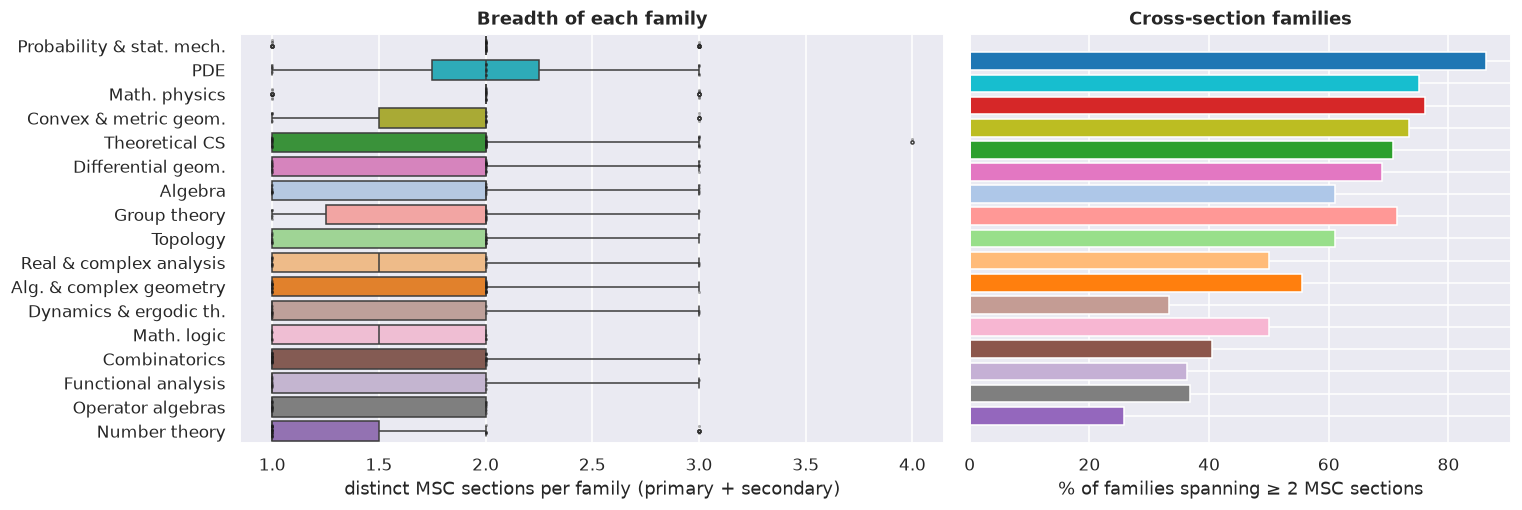

**Broadest families (most MSC sections touched)**

,family,title,subject,n_msc_sections,sections
0,142,Deterministic polynomial factorization over prime fields,Theoretical CS,4,"11 Number theory, 12 Field theory and p, 13 Commutative algebr, 68 Computer science"
1,8,The Deligne–Drinfeld conjecture,Number theory,3,"11 Number theory, 14 Algebraic geometry, 17 Nonassociative rin"
2,9,Function-field reconstruction from Milnor K-theory and Galois data,Number theory,3,"12 Field theory and p, 14 Algebraic geometry, 19 K-theory"
3,31,Uchida’s conjecture for open homomorphisms of Galois groups,Number theory,3,"11 Number theory, 12 Field theory and p, 14 Algebraic geometry"
4,52,Tangent splittings and product decompositions,Alg. & complex geometry,3,"14 Algebraic geometry, 32 Several complex va, 53 Differential geome"
5,73,The Falconer distance conjecture,Real & complex analysis,3,"28 Measure and integr, 42 Harmonic analysis , 52 Convex and discret"
6,76,Real ultraflat Littlewood polynomials and unbounded binary merit factors,Real & complex analysis,3,"30 Functions of a com, 42 Harmonic analysis , 94 Information and co"
7,93,Dimension-free logarithmic Sobolev inequality for subgaussian log-concave measures,Convex & metric geom.,3,"26 Real functions, 52 Convex and discret, 60 Probability theory"


> **Takeaway.** 58% of families span at least two MSC sections (mean 1.71). The most outward-looking subject is **Probability & stat. mech.** (2.03 sections per family), the most self-contained **Number theory**.

In [17]:
# --- Interdisciplinarity: how many distinct MSC sections does a family touch? -------------------
fam["n_msc_sections"] = fam.msc_sections_all.map(len)
fam["cross_section"] = fam.n_msc_sections > 1
order = fam.groupby("subject").n_msc_sections.mean(
).sort_values(ascending=False).index

fig, ax = plt.subplots(1, 2, figsize=(14, 4.8), gridspec_kw={
                       "width_ratios": [1.3, 1]})
sns.boxplot(data=fam, y="subject", x="n_msc_sections", order=order,
            palette=PAL, ax=ax[0], fliersize=2, linewidth=1)
sns.stripplot(data=fam, y="subject", x="n_msc_sections", order=order,
              color="k", size=2, alpha=.35, jitter=.25, ax=ax[0])
ax[0].set_xlabel("distinct MSC sections per family (primary + secondary)")
ax[0].set_ylabel("")
ax[0].set_title("Breadth of each family")
cs = fam.groupby("subject").cross_section.mean().reindex(order) * 100
ax[1].barh(cs.index[::-1], cs.values[::-1], color=[PAL[s]
           for s in cs.index[::-1]])
ax[1].set_yticklabels([])
ax[1].set_xlabel("% of families spanning ≥ 2 MSC sections")
ax[1].set_title("Cross-section families")
finish(fig, "12_interdisciplinarity")

wide = fam.sort_values(["n_msc_sections", "family"],
                       ascending=[False, True]).head(8)
wide = wide.assign(sections=wide.msc_sections_all.map(lambda l: ", ".join(
    f"{c} {MSC_NAMES[c].split(';')[0].split(',')[0][:18]}" for c in l)))
display(Markdown("**Broadest families (most MSC sections touched)**"))
display(wide[["family", "title", "subject", "n_msc_sections",
        "sections"]].reset_index(drop=True))
takeaway(f"{pct(fam.cross_section.mean(), 0)} of families span at least two MSC sections (mean {fam.n_msc_sections.mean():.2f}). The most outward-looking subject is "
         f"**{order[0]}** ({fam.groupby('subject').n_msc_sections.mean()[order[0]]:.2f} sections per family), the most self-contained **{order[-1]}**.")

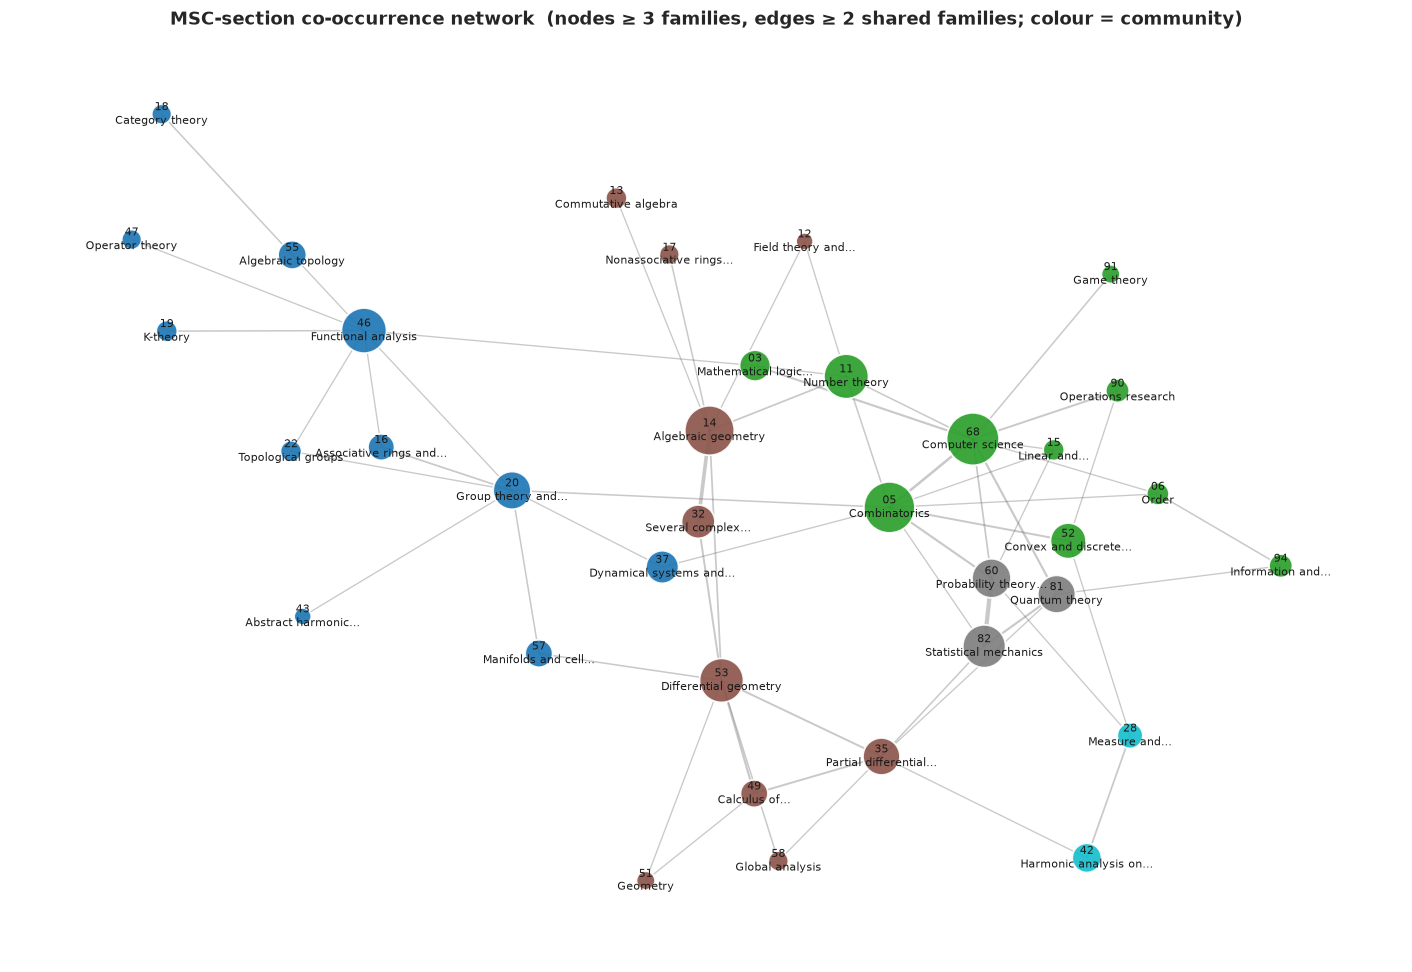

**Most connected sections (hubs) and bridges (betweenness)**

,section,families,weighted_degree,betweenness,community
0,68 Computer science,51,39,0.300,1
1,05 Combinatorics,48,33,0.297,1
2,60 Probability theory and stochastic,27,30,0.171,3
3,14 Algebraic geometry,45,28,0.176,2
4,53 Differential geometry,35,28,0.186,2
5,"82 Statistical mechanics, structure o",33,27,0.097,3
6,35 Partial differential equations,24,19,0.118,2
7,20 Group theory and generalizations,25,18,0.306,0
8,32 Several complex variables and anal,19,18,0.000,2
9,81 Quantum theory,25,16,0.055,3


**Strongest links between sections**

,section A,section B,shared families
0,60 Probability theory and sto,"82 Statistical mechanics, str",16
1,14 Algebraic geometry,32 Several complex variables,13
2,05 Combinatorics,68 Computer science,8
3,05 Combinatorics,60 Probability theory and sto,6
4,03 Mathematical logic and fou,68 Computer science,6
5,81 Quantum theory,"82 Statistical mechanics, str",6
6,68 Computer science,81 Quantum theory,6
7,49 Calculus of variations and,53 Differential geometry,6
8,32 Several complex variables,53 Differential geometry,5
9,68 Computer science,"90 Operations research, mathe",5


> **Takeaway.** The graph splits into 5 communities (modularity 0.50). The strongest link is **60 Probability theory and sto ↔ 82 Statistical mechanics, str** (16 shared families); the top structural bridge (highest betweenness) is **20 Group theory and generalizations**.

In [18]:
# --- Network of MSC sections (edge = two sections assigned to the same family) --------------------
edges = Counter()
for l in fam.msc_sections_all:
    for a, b in itertools.combinations(sorted(l), 2):
        edges[(a, b)] += 1
G = nx.Graph()
for s, n in n_all.items():
    G.add_node(s, n=n)
for (a, b), w in edges.items():
    G.add_edge(a, b, weight=w, dist=1 / w)
MIN_W = 2
H = nx.Graph()
H.add_nodes_from(n for n in G if n_all[n] >= 3)
H.add_edges_from((a, b, d) for a, b, d in G.edges(data=True)
                 if d["weight"] >= MIN_W and a in H and b in H)
H.remove_nodes_from([n for n in list(H) if H.degree(n) == 0])
comms = list(nx.algorithms.community.greedy_modularity_communities(
    H, weight="weight"))
cmap = {n: i for i, c in enumerate(comms) for n in c}
pos = nx.spring_layout(H, weight="weight", k=1.1 /
                       math.sqrt(len(H)), seed=SEED, iterations=300)

fig, ax = plt.subplots(figsize=(13, 9))
w = np.array([H[a][b]["weight"] for a, b in H.edges])
nx.draw_networkx_edges(H, pos, width=0.6 + 2.2 * w /
                       w.max(), alpha=.35, edge_color="#666", ax=ax)
nx.draw_networkx_nodes(H, pos, node_size=[60 + 22 * n_all[n] for n in H], node_color=[
                       cmap[n] for n in H], cmap="tab10", alpha=.92, edgecolors="white", linewidths=1.2, ax=ax)
nx.draw_networkx_labels(H, pos, labels={
                        n: f"{n}\n{textwrap.shorten(MSC_NAMES[n].split(';')[0].split(',')[0], 22, placeholder='…')}" for n in H}, font_size=7, ax=ax)
ax.set_axis_off()
ax.set_title(
    f"MSC-section co-occurrence network  (nodes ≥ 3 families, edges ≥ {MIN_W} shared families; colour = community)")
finish(fig, "13_msc_network")

wd = dict(H.degree(weight="weight"))
bt = nx.betweenness_centrality(H, weight="dist")
cent = pd.DataFrame({"section": [f"{n} {MSC_NAMES[n][:34]}" for n in H], "families": [n_all[n] for n in H], "weighted_degree": [wd[n] for n in H],
                     "betweenness": [round(bt[n], 3) for n in H], "community": [cmap[n] for n in H]}).sort_values("weighted_degree", ascending=False)
top_edges = pd.DataFrame([(f"{a} {MSC_NAMES[a][:26]}", f"{b} {MSC_NAMES[b][:26]}", wgt) for (
    a, b), wgt in edges.most_common(12)], columns=["section A", "section B", "shared families"])
display(Markdown("**Most connected sections (hubs) and bridges (betweenness)**"))
display(cent.head(10).reset_index(drop=True))
display(Markdown("**Strongest links between sections**"))
display(top_edges)
bridge = cent.sort_values("betweenness", ascending=False).iloc[0]
takeaway(f"The graph splits into {len(comms)} communities (modularity {nx.algorithms.community.modularity(H, comms, weight='weight'):.2f}). "
         f"The strongest link is **{top_edges.iloc[0, 0]} ↔ {top_edges.iloc[0, 1]}** ({top_edges.iloc[0, 2]} shared families); the top structural bridge (highest betweenness) is **{bridge.section}**.")

## Text analytics: vocabulary, embeddings, clusters, topics

Here we let the **text alone** speak (algoscript `description`s), ignoring the catalog's subject labels, and then ask *how much of the editorial taxonomy is re-discovered from the words*.

Pipeline: **TF-IDF** (unigrams + bigrams, sublinear term frequency, rare/very common terms pruned) → **truncated SVD** (latent semantic analysis, 100 dims, L2-normalised
so that dot product = cosine similarity) → **t-SNE** for 2-D visualisation, **k-means** for clustering, **NMF** for interpretable topics.

| Method | Question answered |
|---|---|
| Distinctive terms | Which words characterize each subject? |
| Map (t-SNE) | Does the text form visible neighbourhoods that match subjects? |
| k-means vs subject (ARI / NMI) | How closely does unsupervised structure reproduce the catalog taxonomy? |
| Silhouette by subject | Which subjects have a clearly distinct vocabulary and which blur into others? |
| Nearest-neighbour *bridge* analysis | Which algoscripts live next to another subject? |
| NMF topics | Which cross-cutting themes exist beyond subject boundaries? |

In [19]:
def strength(v): return "strongly" if v >= .6 else (
    "moderately" if v >= .4 else "only weakly")


# subjects large enough to be ranked (Math. logic has only a handful of algoscripts)
BIG = subj.index[subj.algoscripts >= 15]

STOP = list(ENGLISH_STOP_WORDS | {"prove", "proves", "proved", "proving", "show", "shows", "shown", "result", "results", "theorem", "paper", "every", "fixed",
                                  "arbitrary", "also", "give", "gives", "given", "use", "uses", "using", "new", "main", "hold", "holds", "exist", "exists", "establish", "establishes",
                                  "resolve", "resolves", "resolving", "construct", "constructs", "consequently", "particular", "including", "allow", "allows", "conjecture", "problem",
                                  "proof", "family", "answer", "answers", "positive", "absolute", "universal", "sufficiently", "large", "small", "contrast", "consequence", "thus"})
tfidf = TfidfVectorizer(stop_words=STOP, ngram_range=(1, 2), min_df=3, max_df=0.4, sublinear_tf=True,
                        token_pattern=r"(?u)\b[^\W\d_]{2,}(?:[-’'][^\W\d_]+)*\b")
X = tfidf.fit_transform(df.description)
terms = np.array(tfidf.get_feature_names_out())
print(
    f"TF-IDF matrix: {X.shape[0]} documents × {X.shape[1]} terms  (density {X.nnz / np.prod(X.shape):.2%})")

rows = []
for s in SUBJECTS:
    m = (df.subject == s).values
    diff = np.asarray(X[m].mean(0)).ravel() - np.asarray(X[~m].mean(0)).ravel()
    rows.append((s, int(m.sum()), ", ".join(terms[np.argsort(-diff)[:9]])))
display(Markdown("**Most distinctive terms per subject** (mean TF-IDF inside the subject minus mean outside)"))
display(pd.DataFrame(rows, columns=[
        "subject", "algoscripts", "distinctive terms"]).set_index("subject"))

TF-IDF matrix: 721 documents × 2121 terms  (density 1.17%)


**Most distinctive terms per subject** (mean TF-IDF inside the subject minus mean outside)

,algoscripts,distinctive terms
subject,,
Probability & stat. mech.,105,"critical, temperature, convergence, inverse temperature, law, model, inverse, limit, converges"
Alg. & complex geometry,86,"projective, complex, bundle, smooth, projective complex, rational, nef, variety, dimension"
Theoretical CS,74,"algorithm, bit, polynomial, binary, deterministic, time, randomized, np-hard, graphs"
Math. physics,59,"quantum, state, future, penrose, ground, mass, thermodynamic, three-dimensional, spin"
Number theory,58,"primes, prime, curve, fields, function, curves, elliptic, hecke, adic"
Combinatorics,50,"graph, vertices, number, integer, ramsey, set, chromatic, erdős, covering"
Differential geom.,49,"metric, curvature, smooth, closed, riemannian, manifold, euclidean, dimension, smooth riemannian"
Operator algebras,31,"algebra, separable, unital, algebras, von neumann, von, neumann, nuclear, neumann algebras"
Convex & metric geom.,30,"distortion, convex, body, convex body, real, ℝⁿ, linear, body ℝⁿ, logarithmic"


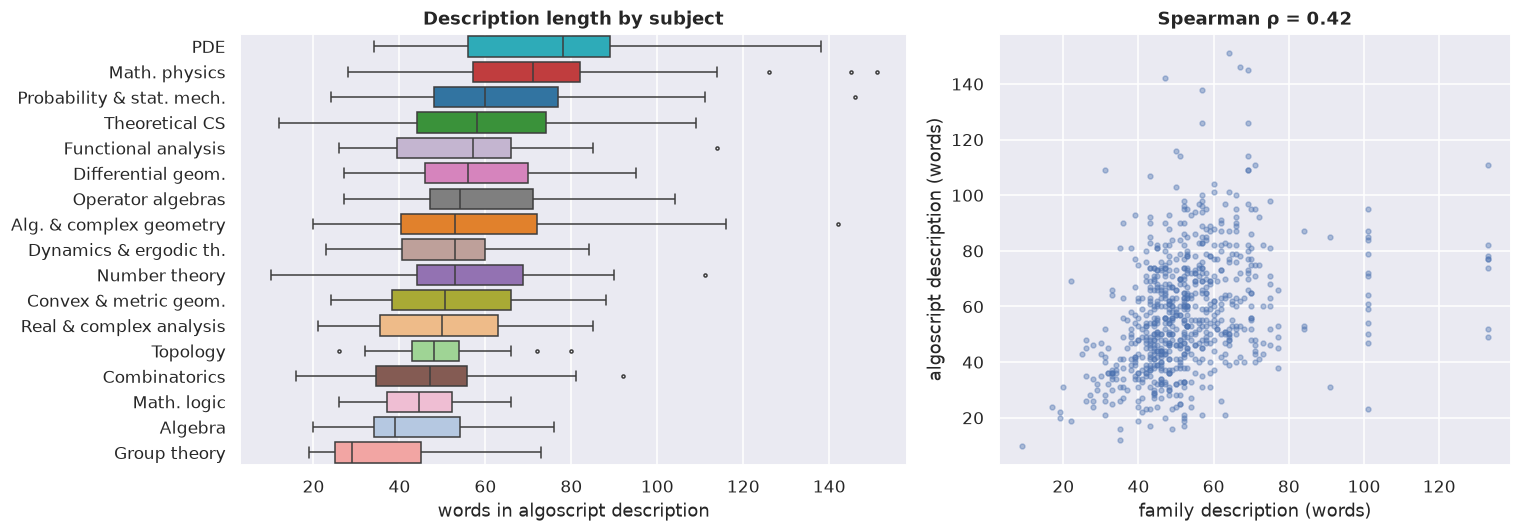

> **Takeaway.** Median algoscript description: 55 words; **PDE** descriptions are the longest (median 78), **Group theory** the shortest (29). algoscript and family description lengths are moderately related (ρ = 0.42).

In [20]:
order_len = df.groupby("subject").n_words.median(
).sort_values(ascending=False).index
fig, ax = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={
                       "width_ratios": [1.3, 1]})
sns.boxplot(data=df, y="subject", x="n_words", order=order_len,
            palette=PAL, ax=ax[0], fliersize=2, linewidth=1)
ax[0].set_xlabel("words in algoscript description")
ax[0].set_ylabel("")
ax[0].set_title("Description length by subject")
ax[1].scatter(df.fam_n_words, df.n_words, s=10, alpha=.4, color="#4C72B0")
rho = df[["fam_n_words", "n_words"]].corr(method="spearman").iloc[0, 1]
ax[1].set_xlabel("family description (words)")
ax[1].set_ylabel("algoscript description (words)")
ax[1].set_title(f"Spearman ρ = {rho:.2f}")
finish(fig, "14_description_length")
takeaway(f"Median algoscript description: {df.n_words.median():.0f} words; **{order_len[0]}** descriptions are the longest (median {df.groupby('subject').n_words.median()[order_len[0]]:.0f}), "
         f"**{order_len[-1]}** the shortest ({df.groupby('subject').n_words.median()[order_len[-1]]:.0f}). "
         f"algoscript and family description lengths are {'weakly' if abs(rho) < .3 else 'moderately'} related (ρ = {rho:.2f}).")

SVD keeps 42.0% of the TF-IDF variance in 100 dimensions


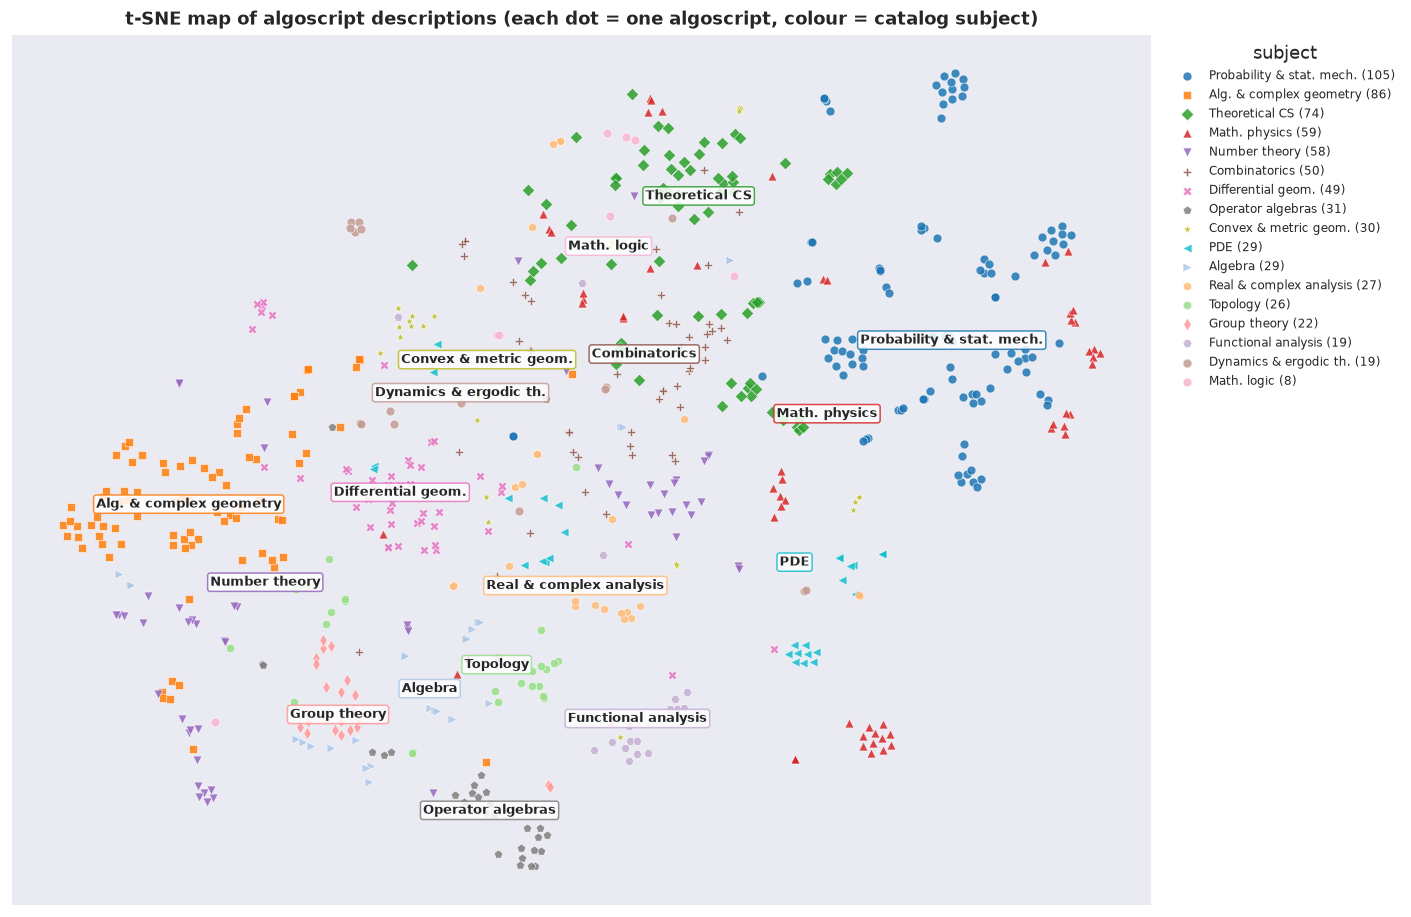

In [21]:
svd = TruncatedSVD(n_components=100, random_state=SEED)
Z = normalize(svd.fit_transform(X))
print(
    f"SVD keeps {svd.explained_variance_ratio_.sum():.1%} of the TF-IDF variance in 100 dimensions")

E = TSNE(n_components=2, perplexity=30, init="pca", learning_rate="auto",
         random_state=SEED, metric="cosine").fit_transform(Z)
df["tsne_x"], df["tsne_y"] = E[:, 0], E[:, 1]

fig, ax = plt.subplots(figsize=(13, 8.5))
for s in SUBJECTS:
    m = df.subject == s
    ax.scatter(df.tsne_x[m], df.tsne_y[m], s=34, alpha=.85, color=PAL[s],
               marker=MARK[s], label=f"{s} ({m.sum()})", edgecolors="white", linewidths=.4)
for s in SUBJECTS:
    m = df.subject == s
    cx_, cy_ = df.tsne_x[m].median(), df.tsne_y[m].median()
    ax.text(cx_, cy_, s, fontsize=8.5, weight="bold", ha="center", va="center",
            bbox=dict(boxstyle="round,pad=.2", fc="white", ec=PAL[s], alpha=.85))
ax.set_xticks([])
ax.set_yticks([])
ax.set_title(
    "t-SNE map of algoscript descriptions (each dot = one algoscript, colour = catalog subject)")
ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left",
          fontsize=8, frameon=False, title="subject")
finish(fig, "15_tsne_map")

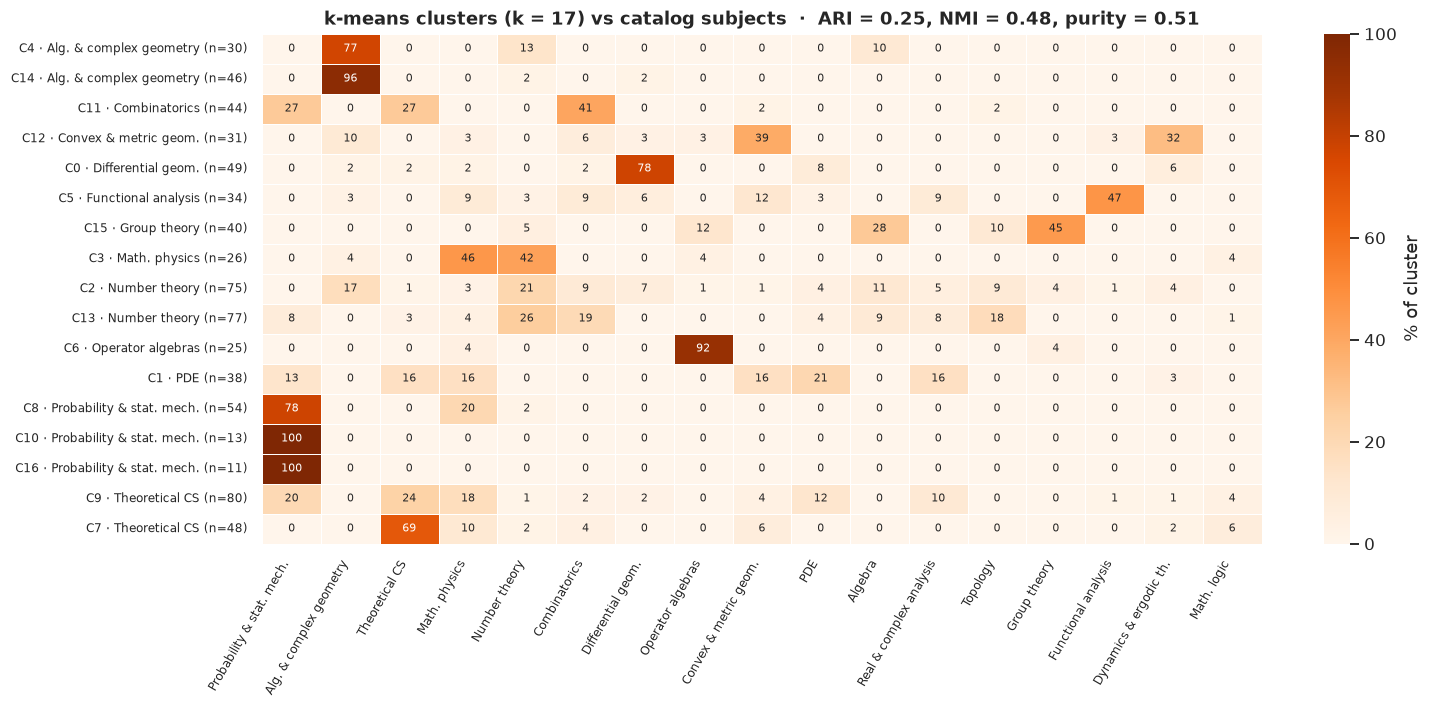

> **Takeaway.** With *no access to labels*, k-means on the text recovers the editorial taxonomy **moderately** (NMI 0.48, purity 51%; a random assignment would give ≈ 0). The imperfect match (ARI 0.25) reflects overlapping vocabularies and families filed under a subject that differs from their closest textual neighbours -see the bridge analysis below.

In [22]:
# --- how much of the catalog taxonomy does unsupervised structure recover? ----------------------------
K = len(SUBJECTS)
km = KMeans(n_clusters=K, n_init=20, random_state=SEED).fit(Z)
df["cluster"] = km.labels_
ari = adjusted_rand_score(df.subject, df.cluster)
nmi = normalized_mutual_info_score(df.subject, df.cluster)
ctab = pd.crosstab(df.cluster, df.subject)
purity = ctab.max(axis=1).sum() / ctab.values.sum()

# label each cluster with its dominant subject and size; order clusters by dominant subject for a block-diagonal look
dom_subject = ctab.idxmax(axis=1)
order_c = dom_subject.sort_values().index
norm = ctab.div(ctab.sum(axis=1), axis=0).loc[order_c][SUBJECTS] * 100
ylabels = [f"C{c} · {dom_subject[c]} (n={ctab.loc[c].sum()})" for c in order_c]

fig, ax = plt.subplots(figsize=(14, 6.6))
sns.heatmap(norm, annot=True, fmt=".0f", cmap="Oranges", vmin=0, vmax=100,
            linewidths=.4, cbar_kws={"label": "% of cluster"}, annot_kws={"fontsize": 7}, ax=ax)
ax.set_yticklabels(ylabels, rotation=0, fontsize=8)
ax.set_xticklabels(SUBJECTS, rotation=60, ha="right", fontsize=8)
ax.set_title(
    f"k-means clusters (k = {K}) vs catalog subjects  ·  ARI = {ari:.2f}, NMI = {nmi:.2f}, purity = {purity:.2f}")
ax.set_xlabel("")
ax.set_ylabel("")
finish(fig, "16_clusters_vs_subjects")
takeaway(f"With *no access to labels*, k-means on the text recovers the editorial taxonomy **{strength(nmi)}** (NMI {nmi:.2f}, purity {pct(purity, 0)}; a random assignment would give ≈ 0). "
         f"The imperfect match (ARI {ari:.2f}) reflects overlapping vocabularies and families filed under a subject that differs from their closest textual neighbours -see the bridge analysis below.")

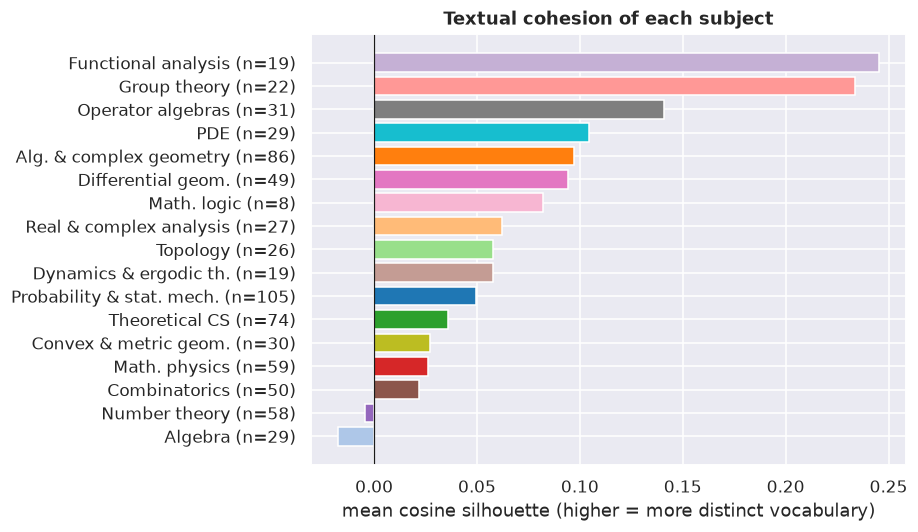

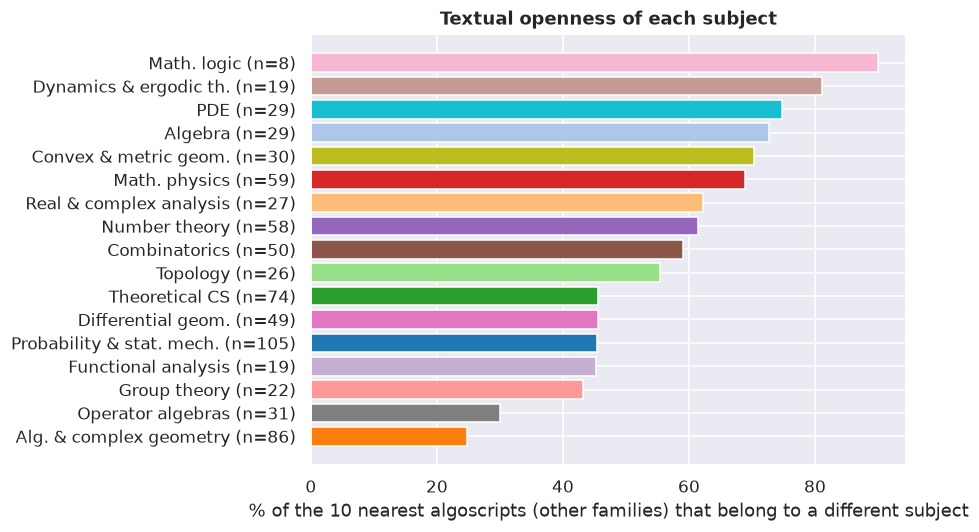

**Bridge algoscripts** — closest textual neighbours mostly come from *other* subjects

,paper_name,subject,cross_subject_nn_rate,neighbour subjects
0,A torsion-free counterexample to reduced Baum–Connes injectivity,Operator algebras,1.0,"Group theory ×5, Algebra ×3, Topology ×2"
1,A torsion-free counterexample to the Kadison–Kaplansky projection conjecture,Operator algebras,1.0,"Group theory ×7, Algebra ×3"
2,A polynomial-time construction of strong thin trees,Combinatorics,1.0,Theoretical CS ×10
3,Counterexamples to the duality conjecture for metric entropy,Functional analysis,1.0,"Convex & metric geom. ×8, Theoretical CS ×1, PDE ×1"
4,Polynomial removal fails for ordered binary matrices,Combinatorics,1.0,"Theoretical CS ×5, Probability & stat. mech. ×2, Math. physics ×2"
5,An irrational-trace counterexample to reduced Baum–Connes,Operator algebras,1.0,"Group theory ×5, Algebra ×3, Topology ×2"
6,A translational tile with no fully periodic tiling in dimension three,Combinatorics,1.0,"Dynamics & ergodic th. ×3, PDE ×3, Differential geom. ×2"
7,Arithmeticity of twisted finite correspondences for lattices over local fields,Operator algebras,1.0,"Number theory ×5, Group theory ×3, Algebra ×1"
8,Conformal flow and the Riemannian Penrose inequality with minimizing frontiers,Math. physics,1.0,Differential geom. ×10
9,Path selection and an elliptic inequality on degenerating Ricci-flat trees,Differential geom.,1.0,"Functional analysis ×3, Real & complex analysis ×3, Group theory ×2"


> **Takeaway.** Nearest neighbours (outside the paper's own family) share the paper's subject 48% of the time versus 8% expected by chance (≈ 6× chance): topical homophily is clear. Among subjects with ≥ 15 algoscripts the most textually *open* is **Dynamics & ergodic th.** (81% of neighbours elsewhere); the most *self-contained* is **Alg. & complex geometry** (25%). Very small subjects (e.g. Math. logic, n = 8) are shown but not ranked.

In [23]:
# --- cohesion: silhouette per subject (cosine) ----------------------------------------------------
sil = pd.Series(silhouette_samples(
    Z, df.subject, metric="cosine"), index=df.index)
df["silhouette"] = sil
sil_s = sil.groupby(df.subject).mean().sort_values()
fig, ax = plt.subplots(figsize=(8.5, 5))
ax.barh([f"{s} (n={subj.algoscripts[s]})" for s in sil_s.index],
        sil_s.values, color=[PAL[s] for s in sil_s.index])
ax.axvline(0, color="k", lw=.8)
ax.set_xlabel("mean cosine silhouette (higher = more distinct vocabulary)")
ax.set_title("Textual cohesion of each subject")
finish(fig, "17_silhouette")

# --- bridge papers: nearest neighbours (excluding the paper's own family) that belong to other subjects --
S = Z @ Z.T
fam_arr = df.result_family_number.to_numpy()
subj_arr = df.subject.to_numpy(dtype=object)
# ignore same-family neighbours (they trivially agree)
S[fam_arr[:, None] == fam_arr[None, :]] = -1
KNN = 10
nn = np.argsort(-S, axis=1)[:, :KNN]
df["cross_subject_nn_rate"] = (subj_arr[nn] != subj_arr[:, None]).mean(axis=1)
homophily = 1 - df.cross_subject_nn_rate.mean()
# P(two random papers share a subject)
baseline = float(((df.subject.value_counts(normalize=True)) ** 2).sum())

open_rate = df.groupby(
    "subject").cross_subject_nn_rate.mean().sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(8.5, 5))
ax.barh([f"{s} (n={subj.algoscripts[s]})" for s in open_rate.index[::-1]],
        open_rate.values[::-1] * 100, color=[PAL[s] for s in open_rate.index[::-1]])
ax.set_xlabel(
    f"% of the {KNN} nearest algoscripts (other families) that belong to a different subject")
ax.set_title("Textual openness of each subject")
finish(fig, "18_openness")

br = df.sort_values(["cross_subject_nn_rate", "silhouette"],
                    ascending=[False, True]).head(12).copy()
br["neighbour subjects"] = [", ".join(f"{s} ×{c}" for s, c in Counter(
    subj_arr[nn[i]]).most_common(3)) for i in br.index]
display(Markdown(
    "**Bridge algoscripts** — closest textual neighbours mostly come from *other* subjects"))
display(br[["paper_name", "subject", "cross_subject_nn_rate", "neighbour subjects"]].assign(
    cross_subject_nn_rate=lambda d: d.cross_subject_nn_rate.round(2)).reset_index(drop=True))
ranked = open_rate[open_rate.index.isin(BIG)]
takeaway(f"Nearest neighbours (outside the paper's own family) share the paper's subject {pct(homophily, 0)} of the time versus {pct(baseline, 0)} expected by chance "
         f"(≈ {homophily / baseline:.0f}× chance): topical homophily is clear. Among subjects with ≥ 15 algoscripts the most textually *open* is **{ranked.index[0]}** "
         f"({pct(ranked.iloc[0], 0)} of neighbours elsewhere); the most *self-contained* is **{ranked.index[-1]}** ({pct(ranked.iloc[-1], 0)}). Very small subjects (e.g. {subj.index[-1]}, n = {subj.algoscripts.iloc[-1]}) are shown but not ranked.")

,topic,algoscripts,dominant subject,purity,top terms
0,"T3: characteristic, algebraically, algebraically closed",33,Alg. & complex geometry,78.8%,"characteristic, algebraically, algebraically closed, log, cartier, field, nef, log canonical"
1,"T7: projective, complex, smooth",51,Alg. & complex geometry,88.2%,"projective, complex, smooth, projective complex, bundle, connected, variety, smooth connected"
2,"T10: graph, graphs, simple",74,Combinatorics,36.5%,"graph, graphs, simple, vertices, np-hard, constant, number, factor"
3,"T11: exponent, honeycomb, critical",53,Combinatorics,26.4%,"exponent, honeycomb, critical, length, polygons, determine, critical honeycomb, logarithmic"
4,"T0: dimension, smooth, metric",60,Differential geom.,61.7%,"dimension, smooth, metric, curvature, manifold, riemannian, closed, connected"
5,"T2: group, finitely, generated",45,Group theory,44.4%,"group, finitely, generated, finitely generated, presented, finitely presented, finite, groups"
6,"T9: data, mass, future",48,Math. physics,39.6%,"data, mass, future, inequality, penrose, area, spacetime, stated"
7,"T8: prime, local, spectrum",90,Number theory,45.6%,"prime, local, spectrum, nonzero, finite, height, sphere, curve"
8,"T6: space, separable, algebra",77,Operator algebras,31.2%,"space, separable, algebra, real, unital, banach, hilbert, norm"
9,"T4: temperature, limit, inverse temperature",103,Probability & stat. mech.,62.1%,"temperature, limit, inverse temperature, inverse, gaussian, model, convergence, lattice"


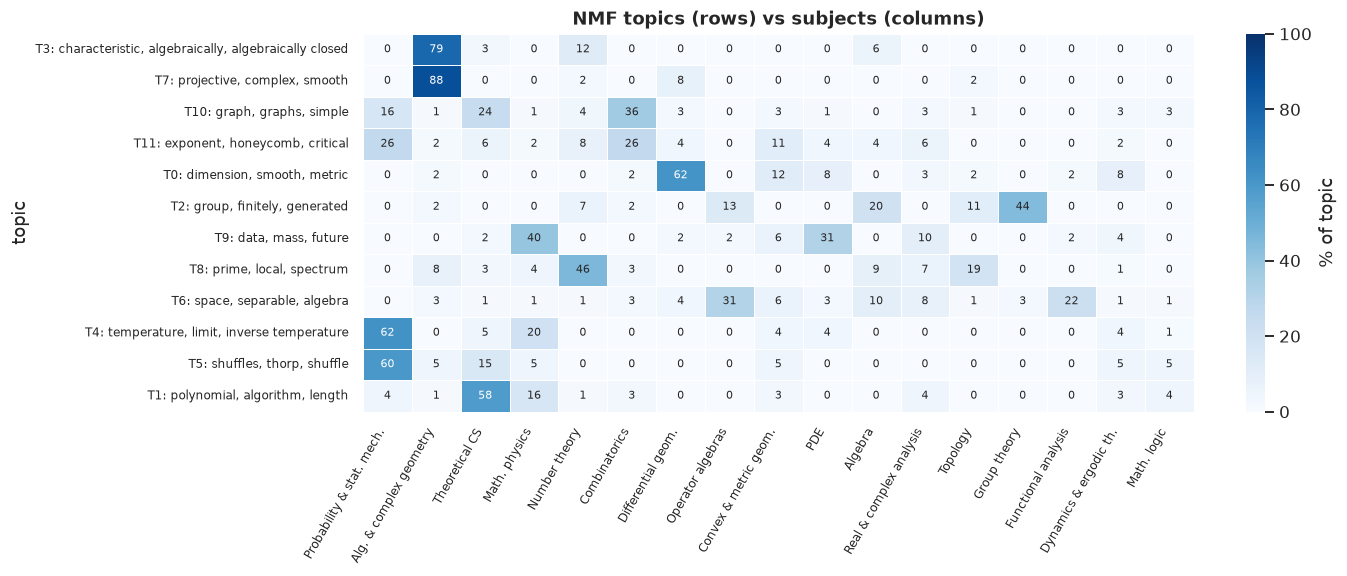

> **Takeaway.** 12 topics summarise the vocabulary. Most are dominated by one subject, but **T11: exponent, honeycomb, critical** is the most *cross-cutting* theme (only 26% of its algoscripts come from its main subject).

In [24]:
# --- NMF topics: soft, interpretable themes that can cut across subjects ---------------------------
K_T = 12
nmf = NMF(n_components=K_T, init="nndsvda", random_state=SEED, max_iter=800)
W = nmf.fit_transform(X); Hm = nmf.components_
df["topic"] = W.argmax(axis=1)
tlabel = {k: f"T{k}: " + ", ".join(terms[np.argsort(-Hm[k])[:3]]) for k in range(K_T)}
tt = pd.crosstab(df.topic, df.subject)
tshare = tt.div(tt.sum(axis=1), axis=0) * 100
ordT = tt.idxmax(axis=1).sort_values().index

topic_table = pd.DataFrame({"topic": [tlabel[k] for k in ordT], "algoscripts": tt.sum(axis=1).loc[ordT].values,
                            "dominant subject": tt.idxmax(axis=1).loc[ordT].values, "purity": (tt.max(axis=1) / tt.sum(axis=1)).loc[ordT].map(pct).values,
                            "top terms": [", ".join(terms[np.argsort(-Hm[k])[:8]]) for k in ordT]})
display(topic_table)

fig, ax = plt.subplots(figsize=(13, 5.4))
sns.heatmap(tshare.loc[ordT][SUBJECTS], annot=True, fmt=".0f", cmap="Blues", vmin=0, vmax=100, linewidths=.4, annot_kws={"fontsize": 7}, cbar_kws={"label": "% of topic"}, ax=ax)
ax.set_yticklabels([tlabel[k] for k in ordT], rotation=0, fontsize=8); ax.set_xticklabels(SUBJECTS, rotation=60, ha="right", fontsize=8)
ax.set_title("NMF topics (rows) vs subjects (columns)"); ax.set_xlabel("")
finish(fig, "19_topics")
mixed = (tt.max(axis=1) / tt.sum(axis=1)).sort_values().index[0]
takeaway(f"{K_T} topics summarise the vocabulary. Most are dominated by one subject, but **{tlabel[mixed]}** is the most *cross-cutting* theme "
         f"(only {pct((tt.max(axis=1) / tt.sum(axis=1))[mixed], 0)} of its algoscripts come from its main subject).")

## Keywords and concept network

`keywords` holds up to six auto-extracted key phrases per algoscript (named results such as *"Cannon's conjecture"* are boosted). We use them
at three levels: **frequency** (what recurs), **spread** (concepts that appear in several subjects are *bridge concepts*) and **co-occurrence**
(which concepts travel together). To avoid double-counting, keyword statistics count families where noted.

4244 keyword assignments · 3532 distinct keywords · 96% appear in only one family (long tail)


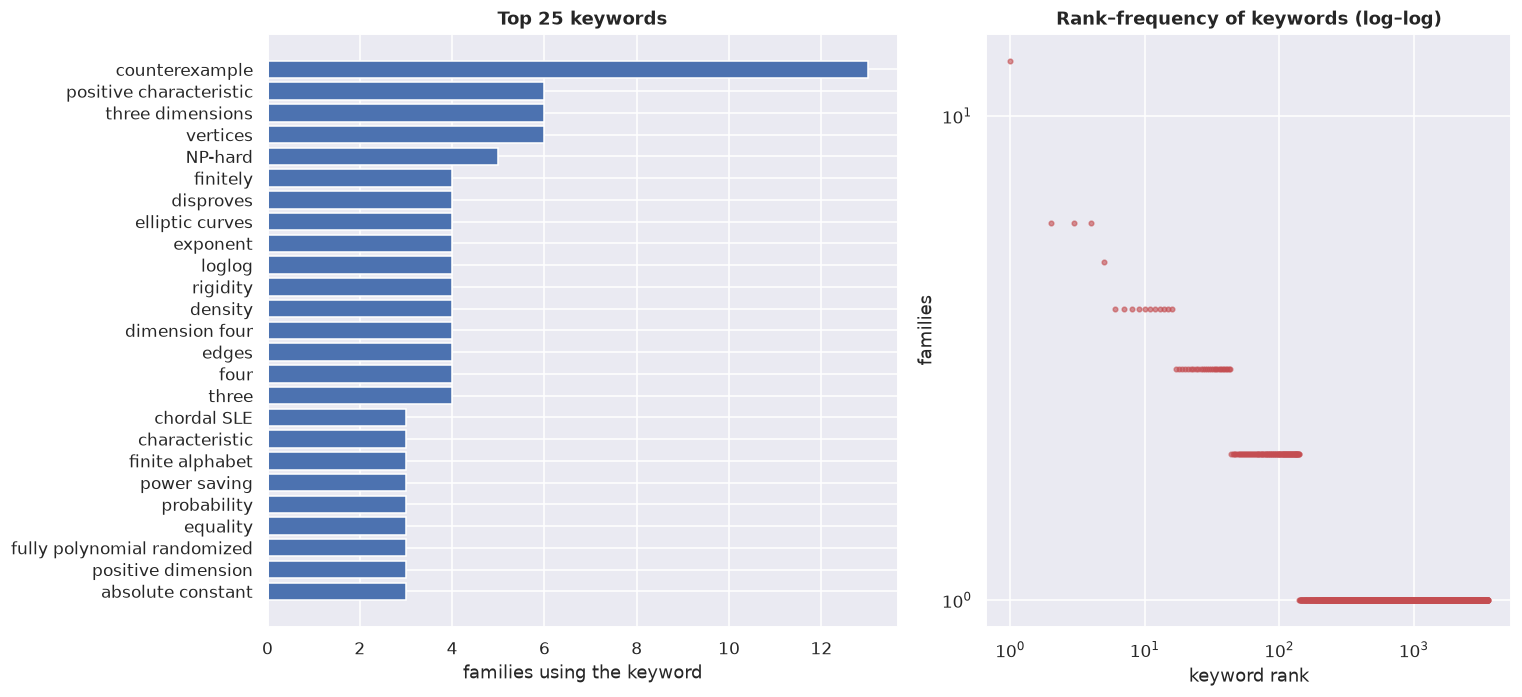

**Bridge concepts** — keywords used in ≥ 3 different subjects

,label,families,algoscripts,subjects
0,counterexample,13,16,7
1,positive characteristic,6,8,4
2,three dimensions,6,8,3
3,finitely,4,7,3
4,disproves,4,5,3
5,exponent,4,5,3
6,loglog,4,5,3
7,rigidity,4,5,4
8,density,4,4,4
9,four,4,4,4


> **Takeaway.** Keyword usage follows a heavy-tailed law: the single most common keyword (*counterexample*) appears in 13 families, while 96% of keywords are family-specific. Only 19 keywords span three or more subjects.

In [25]:
kwdf = df[["paper_name", "result_family_number", "subject", "kw"]].explode("kw").dropna(subset=["kw"])
kwdf["kw_norm"] = kwdf.kw.str.lower().str.replace("–", "-").str.replace("’", "'")
agg = (kwdf.groupby("kw_norm").agg(algoscripts=("paper_name", "nunique"), families=("result_family_number", "nunique"), subjects=("subject", "nunique"), label=("kw", "first"))
         .sort_values(["families", "algoscripts"], ascending=False))
print(f"{len(kwdf)} keyword assignments · {len(agg)} distinct keywords · {pct((agg.families == 1).mean(), 0)} appear in only one family (long tail)")

topk = agg.head(25)[::-1]
fig, ax = plt.subplots(1, 2, figsize=(14, 6.5), gridspec_kw={"width_ratios": [1.2, 1]})
ax[0].barh(topk.label, topk.families, color="#4C72B0"); ax[0].set_xlabel("families using the keyword"); ax[0].set_title("Top 25 keywords")
ranks = np.arange(1, len(agg) + 1)
ax[1].loglog(ranks, agg.families.values, ".", color="#C44E52", alpha=.6); ax[1].set_xlabel("keyword rank"); ax[1].set_ylabel("families"); ax[1].set_title("Rank–frequency of keywords (log–log)")
finish(fig, "20_keywords")

bridgekw = agg[(agg.subjects >= 3)].head(15)[["label", "families", "algoscripts", "subjects"]]
display(Markdown("**Bridge concepts** — keywords used in ≥ 3 different subjects")); display(bridgekw.reset_index(drop=True))
takeaway(f"Keyword usage follows a heavy-tailed law: the single most common keyword (*{agg.label.iloc[0]}*) appears in {agg.families.iloc[0]} families, while "
         f"{pct((agg.families == 1).mean(), 0)} of keywords are family-specific. Only {(agg.subjects >= 3).sum()} keywords span three or more subjects.")

keyword graph: 74 nodes, 119 edges (largest component of the top-120 keywords)


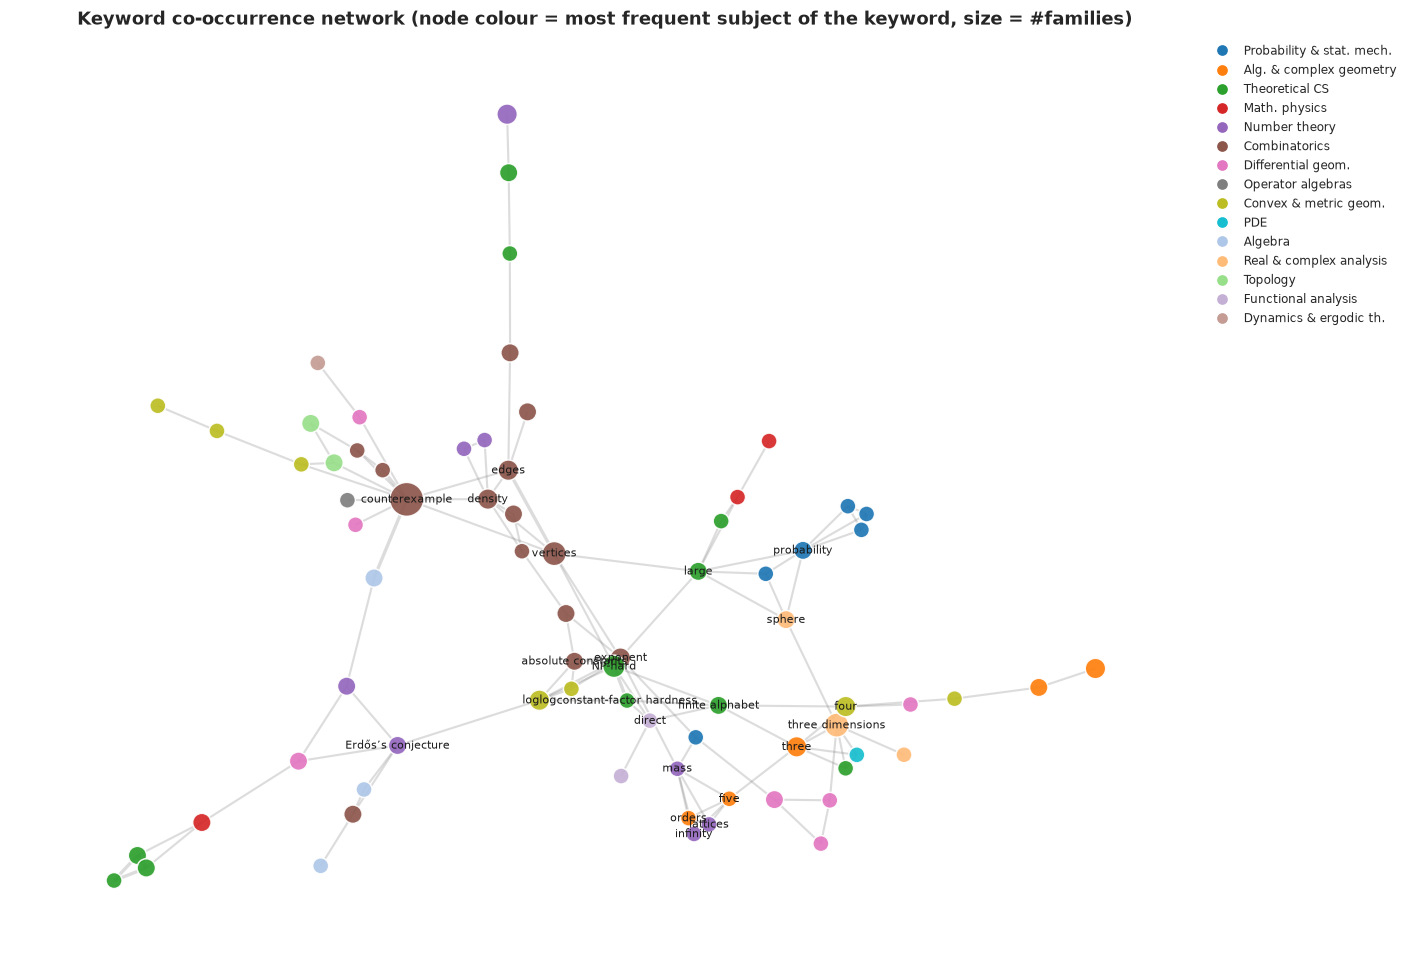

> **Takeaway.** The most central concepts in the co-occurrence network are: *counterexample*, *vertices*, *exponent*, *edges*, *density*, *NP-hard*, *absolute constants*, *loglog*.

**Most frequent named results among the keywords**

,label,families
0,Erdős’s conjecture,3
1,Cardy’s formula,2
2,Gersten’s conjecture,2
3,Bochner–Riesz conjecture,2
4,stronger theorem,2
5,covering conjecture,2
6,Iitaka fibration conjecture,1
7,Penrose inequality,1
8,Milne’s theorems,1
9,Popa’s inequality,1


In [26]:
# --- keyword co-occurrence network (family level) --------------------------------------------------
TOP_N = 120
top_set = set(agg.head(TOP_N).index)
fam_kw = kwdf.groupby("result_family_number").kw_norm.apply(lambda s: sorted(set(s) & top_set))
pair = Counter()
for l in fam_kw:
    for a, b in itertools.combinations(l, 2): pair[(a, b)] += 1
KG = nx.Graph()
for a, b in [p for p, c in pair.items() if c >= 1]: KG.add_edge(a, b, weight=pair[(a, b)])
for n in KG: KG.nodes[n]["families"] = int(agg.families[n]); KG.nodes[n]["subject"] = kwdf[kwdf.kw_norm == n].subject.mode().iloc[0]
cc = max(nx.connected_components(KG), key=len); KG = KG.subgraph(cc).copy()
print(f"keyword graph: {KG.number_of_nodes()} nodes, {KG.number_of_edges()} edges (largest component of the top-{TOP_N} keywords)")

if KG.number_of_edges() >= 5:
    pos = nx.spring_layout(KG, weight="weight", k=1.6 / math.sqrt(len(KG)), seed=SEED, iterations=300)
    fig, ax = plt.subplots(figsize=(13, 9))
    nx.draw_networkx_edges(KG, pos, alpha=.25, width=[.6 + .8 * KG[a][b]["weight"] for a, b in KG.edges], edge_color="#777", ax=ax)
    nx.draw_networkx_nodes(KG, pos, node_size=[40 + 35 * KG.nodes[n]["families"] for n in KG], node_color=[PAL[KG.nodes[n]["subject"]] for n in KG], alpha=.92, edgecolors="white", ax=ax)
    deg = dict(KG.degree()); lab = {n: agg.label[n] for n in KG if deg[n] >= np.percentile(list(deg.values()), 75)}
    nx.draw_networkx_labels(KG, pos, labels=lab, font_size=7, ax=ax)
    ax.set_axis_off(); ax.set_title("Keyword co-occurrence network (node colour = most frequent subject of the keyword, size = #families)")
    handles = [plt.Line2D([], [], marker="o", ls="", color=PAL[s], label=s) for s in SUBJECTS if s in {KG.nodes[n]["subject"] for n in KG}]
    ax.legend(handles=handles, bbox_to_anchor=(1.0, 1), loc="upper left", fontsize=8, frameon=False)
    finish(fig, "21_keyword_network")
    ec = nx.eigenvector_centrality_numpy(KG, weight="weight"); central = sorted(ec, key=ec.get, reverse=True)[:8]
    takeaway(f"The most central concepts in the co-occurrence network are: {', '.join('*' + agg.label[n] + '*' for n in central)}.")
else:
    print("Keyword network too sparse to plot at this threshold.")

named_kw = agg[agg.index.str.contains(r"conjecture|theorem|inequality|problem|formula")].head(12)[["label", "families"]]
display(Markdown("**Most frequent named results among the keywords**")); display(named_kw.reset_index(drop=True))

## Interactive explorer helpers

Small utilities to *use* the dataset interactively. Edit the example calls at the bottom or call them from your own cells:

* `find(query, in_=("paper_name","keywords","description"))` – case-insensitive full-text search (regex allowed).
* `similar(paper_id, k=5)` – the most textually similar algoscripts (cosine similarity on the LSA embedding).
* `show_family(n)` – everything about result family *n*: statement, MSC codes, algoscripts and their links.
* `card(paper_id)` – a compact profile of one algoscript.

In [27]:

def find(query, in_=("paper_name", "keywords", "description"), n=15):
    mask = np.zeros(len(df), bool)
    for c in in_:
        mask |= df[c].str.contains(
            query, case=False, regex=True, na=False).values
    out = df[mask][["paper_name", "subject",
                    "result_family_number", "msc_primary"]]
    print(f"{mask.sum()} algoscripts match {query!r}" +
          (f" (showing {n})" if mask.sum() > n else ""))
    return out.head(n).reset_index(drop=True)


def similar(paper_name, k=5, exclude_same_family=True):
    matches = df.index[df["paper_name"] == paper_name].tolist()
    if not matches:
        raise KeyError(f"{paper_name!r} not found")
    i = matches[0]

    sims = Z @ Z[i]
    sims[i] = -1
    if exclude_same_family:
        sims[(df.result_family_number == df.result_family_number.iloc[i]).values] = -1

    top_ = np.argsort(-sims)[:k]
    res = df.iloc[top_][["paper_name", "subject", "result_family_number"]].assign(
        similarity=sims[top_].round(3)
    )
    print(f"Most similar to {df.paper_name.iloc[i]}: {df.subject.iloc[i]}")
    return res.reset_index(drop=True)


def show_family(n):
    sub = df[df.result_family_number == n]
    if sub.empty:
        raise KeyError(f"family {n} not found")
    r = sub.iloc[0]
    display(Markdown(
        f"### Family {n:03d} - {r.result_family_title}\n"
        f"*{r.main_subject}* · MSC primary **{r.msc_primary}** ({r.msc_primary_section}) · secondary: {r.msc_secondary or '—'}\n\n"
        f"{r.result_family_description}\n\n"
        f"**algoscripts ({len(sub)}):**\n\n"
        + "\n".join(
            f"{j}. [{t}]({u}) - {d:%b %d}"
            for j, (t, u, d) in enumerate(zip(sub.paper_name, sub.paper_url, sub.release), 1)
        )
    ))


def card(paper_name):
    matches = df.index[df["paper_name"] == paper_name].tolist()
    if not matches:
        raise KeyError(f"{paper_name!r} not found")
    r = df.iloc[matches[0]]
    display(Markdown(
        f"**{r.paper_name}**  \n"
        f"*{r.main_subject}* · family {r.result_family_number:03d} · MSC {r.msc_primary} · released {r.release:%b %d, %Y}  \n"
        f"Keywords: {', '.join(r.kw)}  \n\n"
        f"{textwrap.fill(r.description, 140)}"
    ))


# ---- examples ----
display(find("Ramsey"))
q_name = find("Ramsey", n=1).paper_name.iloc[0]
display(similar(q_name, k=5))
show_family(int(fam.sort_values("n_papers", ascending=False).family.iloc[0]))
card(q_name)

5 algoscripts match 'Ramsey'


,paper_name,subject,result_family_number,msc_primary
0,"The sharp logarithmic exponent of r(5,t)",Combinatorics,170,05D10
1,Sharp logarithmic exponents for fixed off-diagonal Ramsey numbers,Combinatorics,170,05D10
2,The hypercube Ramsey number has linear order,Combinatorics,171,05D10
3,A classification of finite Euclidean Ramsey configurations,Combinatorics,172,05D10
4,Cycle--clique Ramsey numbers,Combinatorics,189,05C55


5 algoscripts match 'Ramsey' (showing 1)
Most similar to The sharp logarithmic exponent of r(5,t): Combinatorics


,paper_name,subject,result_family_number,similarity
0,The hypercube Ramsey number has linear order,Combinatorics,171,0.793
1,A classification of finite Euclidean Ramsey configurations,Combinatorics,172,0.501
2,Exact derandomization of logarithmic space: L = RL = BPL,Theoretical CS,103,0.388
3,The irrationality exponent of pi is 2,Number theory,17,0.370
4,Cylinder amplitudes and logarithmic bridge-length windows on the honeycomb lattice,Probability & stat. mech.,237,0.354


### Family 034 - Log abundance for compact Kähler spaces under logarithmic Iitaka subadditivity
*Algebraic and complex geometry* · MSC primary **14E30** (Algebraic geometry) · secondary: 32J25; 14J32

Using logarithmic Iitaka subadditivity, proves log abundance in every dimension for normal compact Kähler log canonical pairs with effective rational boundary: an analytically nef ℚ-Cartier adjoint is semiample. It also proves projective log abundance over every algebraically closed field of characteristic zero and the effective Iitaka fibration conjecture for smooth projective varieties of nonnegative Kodaira dimension in that setting. A further result resolves the finite-rational-coefficient index conjecture for connected projective semi-log-canonical log Calabi–Yau pairs over such fields in each fixed dimension and for each fixed finite set of rational boundary coefficients, with a uniform index independent of the number of components.

**algoscripts (14):**

1. [Log abundance for compact Kähler spaces under logarithmic Iitaka subadditivity](https://github.com/openai/math/blob/main/preprints/Log-abundance-for-compact-Kahler-spaces-under-logarithmic-Iitaka-subadditivity-October-6-2026/main.pdf) - Oct 06
2. [Uniform indices for semi-log-canonical log Calabi–Yau pairs](https://github.com/openai/math/blob/main/preprints/Uniform-indices-for-semi-log-canonical-log-Calabi-Yau-pairs-October-5-2026/uniform-slc-index.pdf) - Oct 05
3. [Conditional good minimal models for compact Kähler fourfolds](https://github.com/openai/math/blob/main/preprints/Conditional-good-minimal-models-for-compact-Kahler-fourfolds-October-6-2026/paper.pdf) - Oct 06
4. [Log abundance in characteristic zero](https://github.com/openai/math/blob/main/preprints/Log-abundance-in-characteristic-zero-September-24-2026/paper.pdf) - Sep 24
5. [Minimal metrics and interior injectivity for nef adjoints](https://github.com/openai/math/blob/main/preprints/Minimal-metrics-and-interior-injectivity-for-nef-adjoints-September-27-2026/paper.pdf) - Sep 27
6. [Fourfold nonvanishing by minimal metrics and moving jets](https://github.com/openai/math/blob/main/preprints/Fourfold-nonvanishing-by-minimal-metrics-and-moving-jets-September-27-2026/paper.pdf) - Sep 27
7. [Lifting sections from the reduced support of an adjoint](https://github.com/openai/math/blob/main/preprints/Lifting-sections-from-the-reduced-support-of-an-adjoint-September-27-2026/paper.pdf) - Sep 27
8. [Schnell fiber spaces and good canonical models](https://github.com/openai/math/blob/main/preprints/Schnell-fiber-spaces-and-good-canonical-models-September-24-2026/paper.pdf) - Sep 24
9. [Uniform log Iitaka fibrations and bounded moduli denominators](https://github.com/openai/math/blob/main/preprints/Uniform-log-Iitaka-fibrations-and-bounded-moduli-denominators-October-4-2026/uniform-log-iitaka.pdf) - Oct 04
10. [Uniform Pluricanonical Iitaka Fibrations](https://github.com/openai/math/blob/main/preprints/Uniform-Pluricanonical-Iitaka-Fibrations-October-3-2026/paper.pdf) - Oct 03
11. [Relative denominators and effective systems for log Calabi-Yau fibrations](https://github.com/openai/math/blob/main/preprints/Relative-denominators-and-effective-systems-for-log-Calabi-Yau-fibrations-September-27-2026/paper.pdf) - Sep 27
12. [Arithmetic Stein-degree bounds for log Calabi–Yau pairs](https://github.com/openai/math/blob/main/preprints/Arithmetic-Stein-degree-bounds-for-log-Calabi-Yau-pairs-September-25-2026/paper.pdf) - Sep 25
13. [Uniform effective log Iitaka fibrations for fourfolds](https://github.com/openai/math/blob/main/preprints/Uniform-effective-log-Iitaka-fibrations-for-fourfolds-September-26-2026/paper.pdf) - Sep 26
14. [Abundance after nonvanishing for compact Kähler fourfolds](https://github.com/openai/math/blob/main/preprints/Abundance-after-nonvanishing-for-compact-Kahler-fourfolds-September-27-2026/paper.pdf) - Sep 27

**The sharp logarithmic exponent of r(5,t)**  
*Combinatorics* · family 170 · MSC 05D10 · released Sep 24, 2026  
Keywords: logarithmic exponent, off-diagonal Ramsey number  

We determine the sharp logarithmic exponent of the off-diagonal Ramsey number r(5,t): r(5,t)=(t⁴)/((log t)³⁺ᵒ⁽¹⁾) (t → ∞).

## Key findings and limitations

The summary below is **generated from the computed results**.

In [28]:
ex_flag = overall.index[-1]
findings = f"""
**Scale & structure**
- The catalog holds **{len(df)} algoscripts** in **{len(fam)} result families** over **{len(SUBJECTS)} subjects**; {pct((fam.n_papers == 1).mean(), 0)} of families rest on one algoscript, while the ten largest
  families contain {pct(top10_share, 0)} of all algoscripts (Gini {GINI:.2f}).
- **{subj.index[0]}** is the largest subject ({pct(subj.share.iloc[0])} of algoscripts); {'it also has' if subj.per_family.idxmax() == subj.index[0] else '**' + subj.per_family.idxmax() + '** has'} the highest documentation intensity ({subj.per_family.max():.2f} algoscripts per family).

**Timing**
- Release was bursty: **{pct(share_b1, 0)}** of algoscripts fall into *{labels[1]}* and **{pct(share_b2, 0)}** into *{labels[3]}*; the peak day has {daily.max()} algoscripts.

**Nature of the claims** *(regex heuristic)*
- The most common claim tag is **{ex_flag.lower()}** ({pct(overall.iloc[-1], 0)} of families); {pct(fam['Disproof / counterexample / negative'].mean(), 0)} of families are negative/disproof-type results,
  most concentrated in **{cx.index[0]}**.

**Mathematical landscape (MSC 2020, curated)**
- {fam.msc_section.nunique()} primary MSC sections are used; subject and MSC are strongly but imperfectly aligned (Cramér's V {cramers_v:.2f}).
- {pct(fam.cross_section.mean(), 0)} of families span ≥ 2 MSC sections; the section network has {len(comms)} communities and its main structural bridge is **{bridge.section}**.

**What the text reveals**
- Unsupervised clustering of descriptions recovers the subject taxonomy {strength(nmi)} (NMI {nmi:.2f}, purity {pct(purity, 0)}); nearest neighbours share a subject {pct(homophily, 0)} of the time
  (chance: {pct(baseline, 0)}). Among subjects with ≥ 15 algoscripts the most textually open is **{ranked.index[0]}**, the most self-contained **{ranked.index[-1]}**.
- Keywords follow a heavy-tailed distribution: {pct((agg.families == 1).mean(), 0)} are specific to a single family, only {(agg.subjects >= 3).sum()} span three or more subjects.
"""
display(Markdown(findings))


**Scale & structure**
- The catalog holds **721 algoscripts** in **373 result families** over **17 subjects**; 55% of families rest on one algoscript, while the ten largest
  families contain 14% of all algoscripts (Gini 0.35).
- **Probability & stat. mech.** is the largest subject (14.6% of algoscripts); it also has the highest documentation intensity (3.62 algoscripts per family).

**Timing**
- Release was bursty: **77%** of algoscripts fall into *Batch 1 (Sep 22–27)* and **22%** into *Batch 2 (Oct 4–7)*; the peak day has 189 algoscripts.

**Nature of the claims** *(regex heuristic)*
- The most common claim tag is **mentions a named conjecture/problem** (67% of families); 27% of families are negative/disproof-type results,
  most concentrated in **Math. logic**.

**Mathematical landscape (MSC 2020, curated)**
- 40 primary MSC sections are used; subject and MSC are strongly but imperfectly aligned (Cramér's V 0.83).
- 58% of families span ≥ 2 MSC sections; the section network has 5 communities and its main structural bridge is **20 Group theory and generalizations**.

**What the text reveals**
- Unsupervised clustering of descriptions recovers the subject taxonomy moderately (NMI 0.48, purity 51%); nearest neighbours share a subject 48% of the time
  (chance: 8%). Among subjects with ≥ 15 algoscripts the most textually open is **Dynamics & ergodic th.**, the most self-contained **Alg. & complex geometry**.
- Keywords follow a heavy-tailed distribution: 96% are specific to a single family, only 19 span three or more subjects.


### Limitations

* **Curated** MSC codes are assigned per family by a third party; alternative reasonable choices would shift §7 somewhat.
* **Heuristic enrichment.** Keywords (RAKE/TF-IDF) and claim-type tags (regex) are approximations. Clusters/topics depend on preprocessing choices and can be refined.
* **Short texts.** Descriptions are ~40–120 words, which limits the resolution of text-embedding methods. A family's algoscripts share much vocabulary.
* **Release date ≠ discovery date.** Dates come from folder names and only measure when items entered the catalog.

In [ ]:
# ------------------------------ optional export of everything derived in this notebook ------------------------------
import scipy
import sklearn
import sys
flag_cols = FLAG_COLS + ["n_msc_sections", "cross_section"]
enriched = (df.drop(columns=["kw", "msc_sec_list", "msc_all_sections", "tsne_x", "tsne_y"])
              .merge(fam[["family"] + flag_cols], left_on="result_family_number", right_on="family", how="left").drop(columns="family"))
enriched["batch"] = enriched.batch.astype(str)
print("enriched table:", enriched.shape, "| new columns:", [
      c for c in enriched.columns if c not in EXPECTED][:20], "…")
if EXPORT_ENRICHED:
    out = DATA_PATH.parent / "OpenAI_math_analysis.csv"
    enriched.to_csv(out, index=False, encoding="utf-8-sig")
    print("written", out)

print(
    f"\nReproducibility : python {sys.version.split()[0]} · pandas {pd.__version__} · numpy {np.__version__} · scikit-learn {sklearn.__version__} · scipy {scipy.__version__} · networkx {nx.__version__} · seed {SEED}")

enriched table: (721, 30) | new columns: ['subject', 'release', 'msc_section', 'n_words', 'fam_n_words', 'batch', 'cluster', 'silhouette', 'cross_subject_nn_rate', 'topic', 'Mentions a named conjecture/problem', 'Disproof / counterexample / negative', 'Sharp / optimal / asymptotic', 'Classification / characterisation', 'Algorithm / complexity', 'Explicit construction', 'n_msc_sections', 'cross_section'] …

Reproducibility : 🍁 python 3.13.5 · pandas 3.1.1 · numpy 2.5.4 · scikit-learn 1.9.1 · scipy 1.18.1 · networkx 3.7 · seed 42


Nov.'26 🍂 - [brk](github.com/hyperphantasia/kaggle)
